<a href="https://colab.research.google.com/github/LeylahfrA01178568/2039_data_visualization/blob/main/Activity_5_A01178568.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 5 : Visualization with histograms and boxplots


**Leylah Fragoso Carvajal #A0117856**

In this activity the file of antropometria will be used in order to answer the following questions:

*Index:*
- [Select important variables](scrollTo=_Wu-4GGYknk8&line=1&uniqifier=1)
- [Variables' visualization](scrollTo=YD2Ooq-t3f4T&line=1&uniqifier=1)
- [Quiz Questions](scrollTo=_6yLriuEqcOD&line=2&uniqifier=1)
- [Distribution diagram, weight vs waist](scrollTo=G0lEU5Gt3Mrp&line=1&uniqifier=1)
- [Answer to questions](scrollTo=N5H0GNhx4Dfe&line=1&uniqifier=1)









In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
path = '/content/antropometria-dataset.csv'
df = pd.read_csv(path)
df.head()

,folio,intp,entidad,desc_ent,sexo,edad,meses,peso,ropa,talla,...,hpresion,tbrazo,htension,PrimaryLast,code_upm,est_dis,est_urb,est_marg,pondef,est_var
0,210295,2,21,PUEBLA,2,38,8,73.70,2,146.4,...,16:30,2,16:35,1,R2101,5,3,1,3470.002176,215
1,101655,3,10,DURANGO,2,11,11,35.65,2,145.1,...,15:25,3,15:25,1,M1041,1,1,1,417.946672,101
2,10287,6,1,AGUASCALIENTES,2,18,8,54.80,1,162.0,...,9:40,1,9:40,1,M0108,5,3,1,472.980811,15
3,91526,4,9,DISTRITO FEDERAL,1,10,8,33.40,2,146.5,...,7:40,3,7:45,1,M0931,4,3,2,1832.581391,94
4,210939,3,21,PUEBLA,2,19,3,97.95,2,161.0,...,6:00,2,6:00,1,M2123,5,3,1,7622.066564,215


In [5]:
df.shape

(18640, 26)

In [6]:
print('The dataset has:', df.shape[0], 'rows and', df.shape[1], 'columns.')


The dataset has: 18640 rows and 26 columns.


In [8]:
df.columns

Index(['folio', 'intp', 'entidad', 'desc_ent', 'sexo', 'edad', 'meses', 'peso',
       'ropa', 'talla', 'emb', 'temb', 'cintura', 'cadera', 'sistol',
       'diastol', 'hpresion', 'tbrazo', 'htension', 'PrimaryLast', 'code_upm',
       'est_dis', 'est_urb', 'est_marg', 'pondef', 'est_var'],
      dtype='object')

## Select important variables

I kept the variables that I understood and the ones that were asked in the quiz

In [9]:
important_columns = ['desc_ent', 'sexo','peso','edad','cadera', 'cintura', 'ropa','talla']
ndf = df[important_columns].copy()
ndf.head()

,desc_ent,sexo,peso,edad,cadera,cintura,ropa,talla
0,PUEBLA,2,73.70,38,106.0,98.7,2,146.4
1,DURANGO,2,35.65,11,75.0,64.0,2,145.1
2,AGUASCALIENTES,2,54.80,18,94.3,67.6,1,162.0
3,DISTRITO FEDERAL,1,33.40,10,72.2,60.6,2,146.5
4,PUEBLA,2,97.95,19,127.0,113.0,2,161.0


### Check missing values

In [10]:
ndf.isnull().sum()

,0
desc_ent,0
sexo,0
peso,0
edad,0
cadera,608
cintura,608
ropa,0
talla,0


## Variables' visualization: box plots, histograms, line plot, bar plot

In [48]:
measurement_columns = ['peso', 'edad', 'cintura', 'cadera', 'talla', 'ropa']

In [49]:
median_overall_table = ndf.pivot_table(
    values=measurement_columns,
    index='desc_ent',
    aggfunc='median'
)

median_overall_table.head()

,cadera,cintura,edad,peso,ropa,talla
desc_ent,,,,,,
AGUASCALIENTES,97.850,88.5,28.0,66.60,2.0,160.0
BAJA CALIFORNIA,99.000,88.8,27.0,67.95,2.0,158.8
BAJA CALIFORNIA SUR,101.050,91.2,29.0,71.25,2.0,160.5
CAMPECHE,98.500,88.6,31.0,64.35,1.0,153.1
CHIAPAS,92.575,82.1,27.5,57.20,2.0,151.0


In [50]:
sum_overall_table = ndf.pivot_table(
    values=measurement_columns,
    index='desc_ent',
    aggfunc='sum'
)
sum_overall_table

,cadera,cintura,edad,peso,ropa,talla
desc_ent,,,,,,
AGUASCALIENTES,61983.75,55974.85,20878,43464.350,1072,104724.55
BAJA CALIFORNIA,54406.66,48672.58,18051,38615.540,868,89789.60
BAJA CALIFORNIA SUR,51863.51,46652.91,16925,38058.875,855,84942.70
CAMPECHE,50502.15,45469.75,18405,35391.395,793,83160.70
CHIAPAS,51794.30,46147.55,19356,35029.175,918,91820.70
CHIHUAHUA,57012.00,51285.10,21033,39127.075,941,93945.70
COAHUILA DE ZARAGOZA,60018.40,54081.40,20343,41710.335,856,97718.95
COLIMA,58342.70,52317.65,21296,41177.445,953,95332.25
DISTRITO FEDERAL,39240.41,35304.26,12992,25526.755,545,61881.00


### Sex division

In [51]:
sex_1 = ndf.loc[ndf['sexo'] == 1].copy()
sex_2 = ndf.loc[ndf['sexo'] == 2].copy()

#### Sex 1

In [52]:
median_sex1 = sex_1.pivot_table(
    values=measurement_columns,
    index='desc_ent',
    aggfunc='median'
)
median_sex1

,cadera,cintura,edad,peso,ropa,talla
desc_ent,,,,,,
AGUASCALIENTES,95.650,89.425,28.5,69.9500,2.0,167.600
BAJA CALIFORNIA,97.600,89.800,25.0,70.6500,2.0,165.600
BAJA CALIFORNIA SUR,100.300,92.500,29.0,76.6500,2.0,167.950
CAMPECHE,96.900,91.000,33.0,67.3500,1.0,159.900
CHIAPAS,91.000,79.925,24.0,59.2000,2.0,158.350
CHIHUAHUA,97.400,88.500,32.0,69.3000,2.0,166.950
COAHUILA DE ZARAGOZA,96.400,89.000,26.0,68.3000,1.0,166.500
COLIMA,98.050,91.300,30.0,71.7000,2.0,166.550
DISTRITO FEDERAL,96.525,90.350,26.0,69.0000,1.0,165.650


In [53]:
sum_sex1 = sex_1.pivot_table(
    values=measurement_columns,
    index='desc_ent',
    aggfunc='sum'
)
sum_sex1

,cadera,cintura,edad,peso,ropa,talla
desc_ent,,,,,,
AGUASCALIENTES,28806.20,26681.50,9610,21135.585,493,49958.70
BAJA CALIFORNIA,26003.84,23790.44,8268,18847.440,402,43402.65
BAJA CALIFORNIA SUR,26078.81,24100.16,8586,19721.425,415,43182.80
CAMPECHE,22871.05,21343.00,8548,16263.565,350,37540.45
CHIAPAS,22288.30,20133.50,8011,14474.575,378,38755.70
CHIHUAHUA,25610.30,23674.60,9348,18256.550,415,43828.80
COAHUILA DE ZARAGOZA,28748.90,26555.40,9766,20593.055,417,49295.20
COLIMA,25553.75,23689.90,9272,18672.705,410,43295.60
DISTRITO FEDERAL,16796.40,15559.15,5983,12086.155,247,28465.65


#### Sex 2

In [54]:
median_sex2 = sex_2.pivot_table(
    values=measurement_columns,
    index='desc_ent',
    aggfunc='median'
)
median_sex2

,cadera,cintura,edad,peso,ropa,talla
desc_ent,,,,,,
AGUASCALIENTES,100.000,88.150,28.0,63.7000,2.0,155.450
BAJA CALIFORNIA,100.500,88.250,29.5,64.2000,2.0,154.425
BAJA CALIFORNIA SUR,101.800,90.000,29.0,68.5500,2.0,155.500
CAMPECHE,99.975,87.225,30.0,62.3750,1.0,149.900
CHIAPAS,94.550,83.225,28.0,56.0250,1.5,148.175
CHIHUAHUA,100.600,88.000,34.0,64.6250,2.0,156.500
COAHUILA DE ZARAGOZA,102.400,90.800,33.0,67.3000,1.0,155.250
COLIMA,102.600,90.250,34.0,66.0000,2.0,154.800
DISTRITO FEDERAL,99.900,86.600,26.0,61.4500,1.0,153.200


In [55]:
sum_sex2 = sex_2.pivot_table(
    values=measurement_columns,
    index='desc_ent',
    aggfunc='sum'
)
sum_sex2

,cadera,cintura,edad,peso,ropa,talla
desc_ent,,,,,,
AGUASCALIENTES,33177.55,29293.35,11268,22328.765,579,54765.85
BAJA CALIFORNIA,28402.82,24882.14,9783,19768.100,466,46386.95
BAJA CALIFORNIA SUR,25784.70,22552.75,8339,18337.450,440,41759.90
CAMPECHE,27631.10,24126.75,9857,19127.830,443,45620.25
CHIAPAS,29506.00,26014.05,11345,20554.600,540,53065.00
CHIHUAHUA,31401.70,27610.50,11685,20870.525,526,50116.90
COAHUILA DE ZARAGOZA,31269.50,27526.00,10577,21117.280,439,48423.75
COLIMA,32788.95,28627.75,12024,22504.740,543,52036.65
DISTRITO FEDERAL,22444.01,19745.11,7009,13440.600,298,33415.35


### *Boxplots*

Individual measurements boxplots

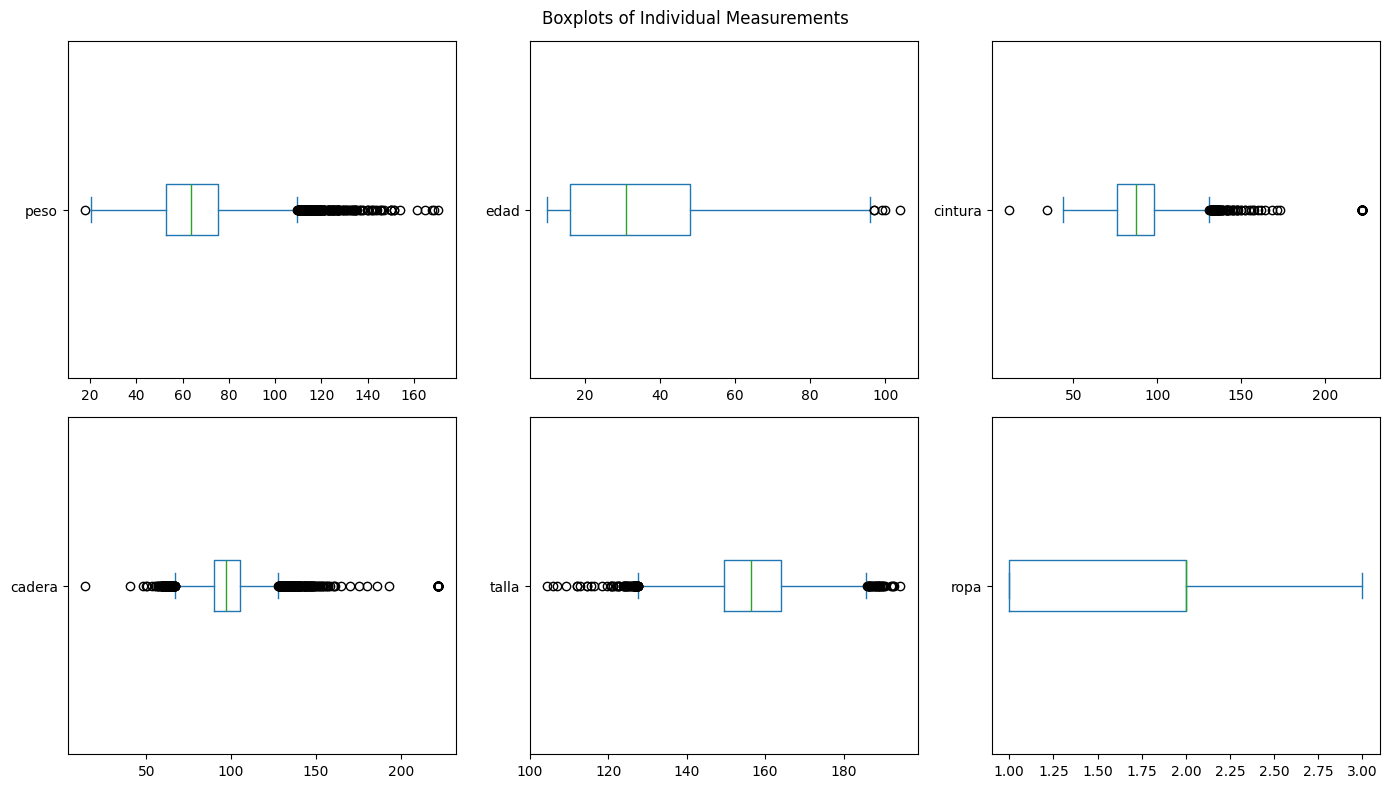

In [56]:
ndf[measurement_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    vert=False,
    sharex=False,
    sharey=False

)

plt.suptitle('Boxplots of Individual Measurements')
plt.tight_layout()
plt.show()

#### Sex 1

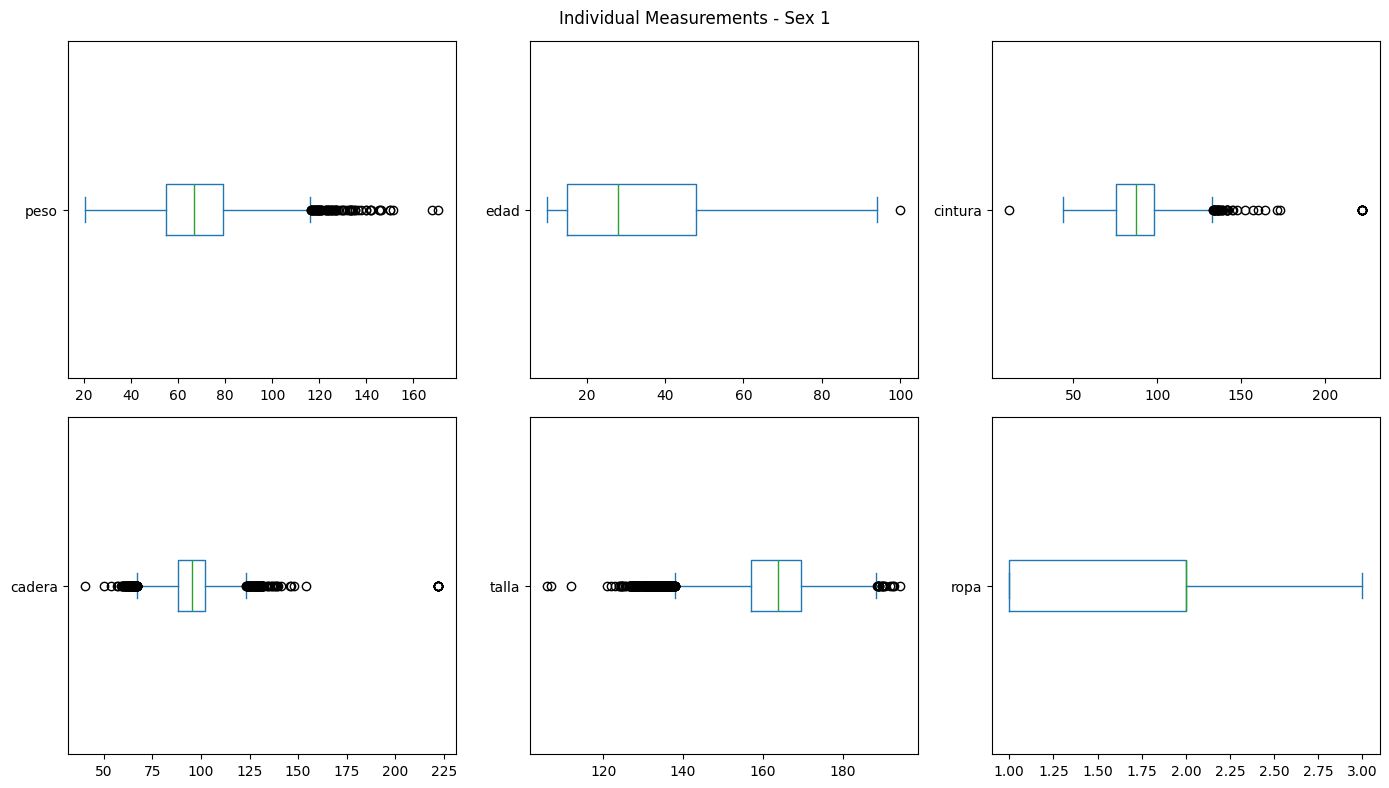

In [57]:
sex_1[measurement_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    vert=False,
    sharex=False,
    sharey=False
)

plt.suptitle('Individual Measurements - Sex 1')
plt.tight_layout()
plt.show()

#### Sex 2

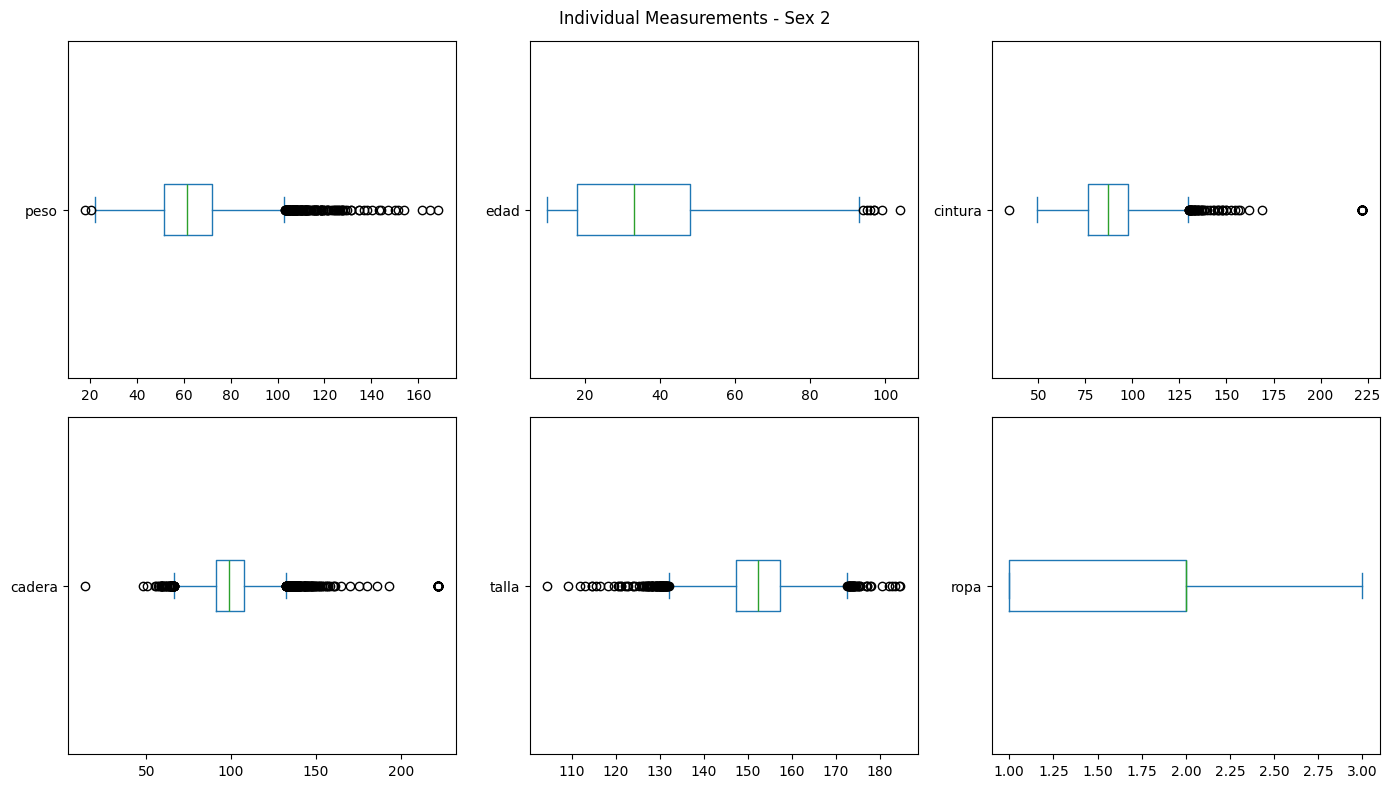

In [58]:
sex_2[measurement_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    vert=False,
    sharex=False,
    sharey=False
)

plt.suptitle('Individual Measurements - Sex 2')
plt.tight_layout()
plt.show()

Median boxplots

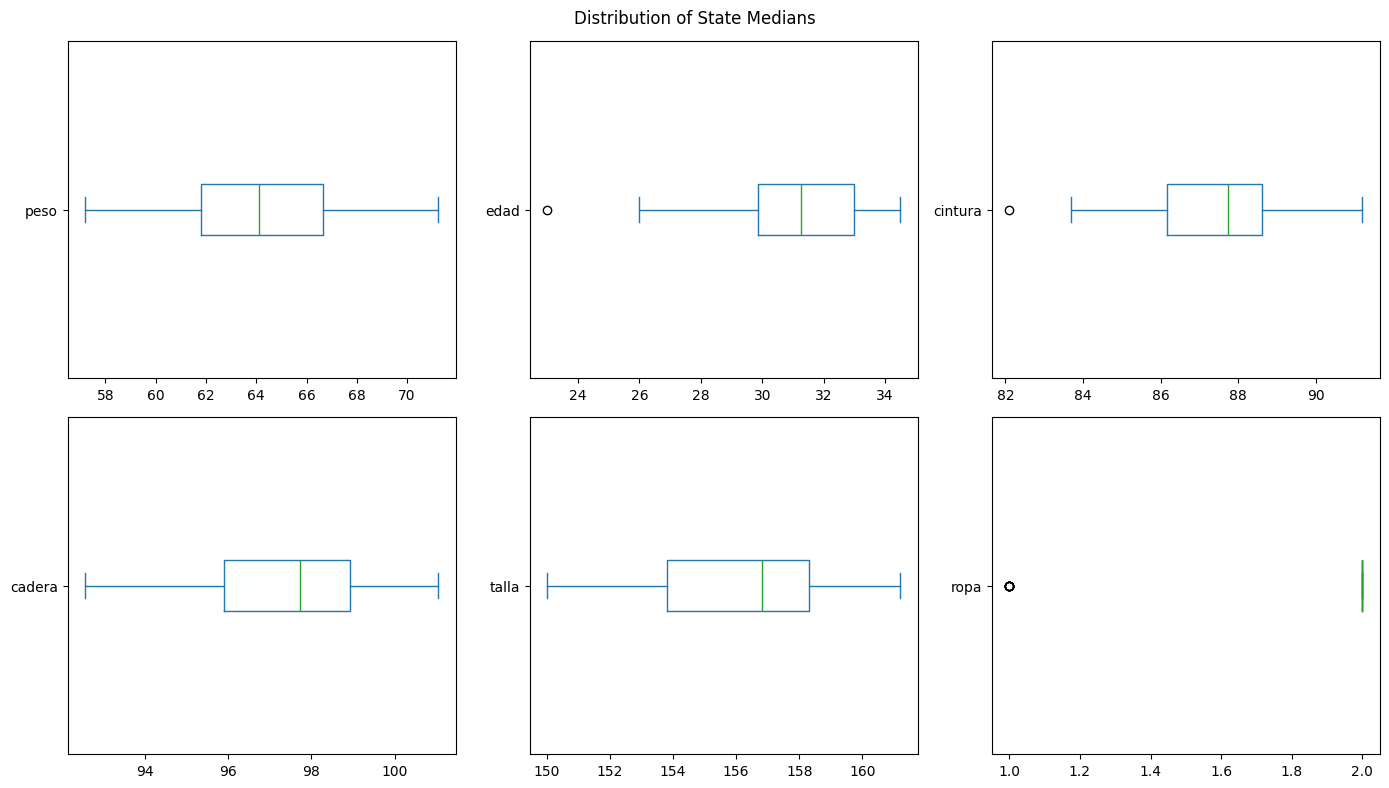

In [59]:
median_overall_table[measurement_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    vert=False,
    sharex=False,
    sharey=False
)

plt.suptitle('Distribution of State Medians')
plt.tight_layout()
plt.show()

#### Sex 1

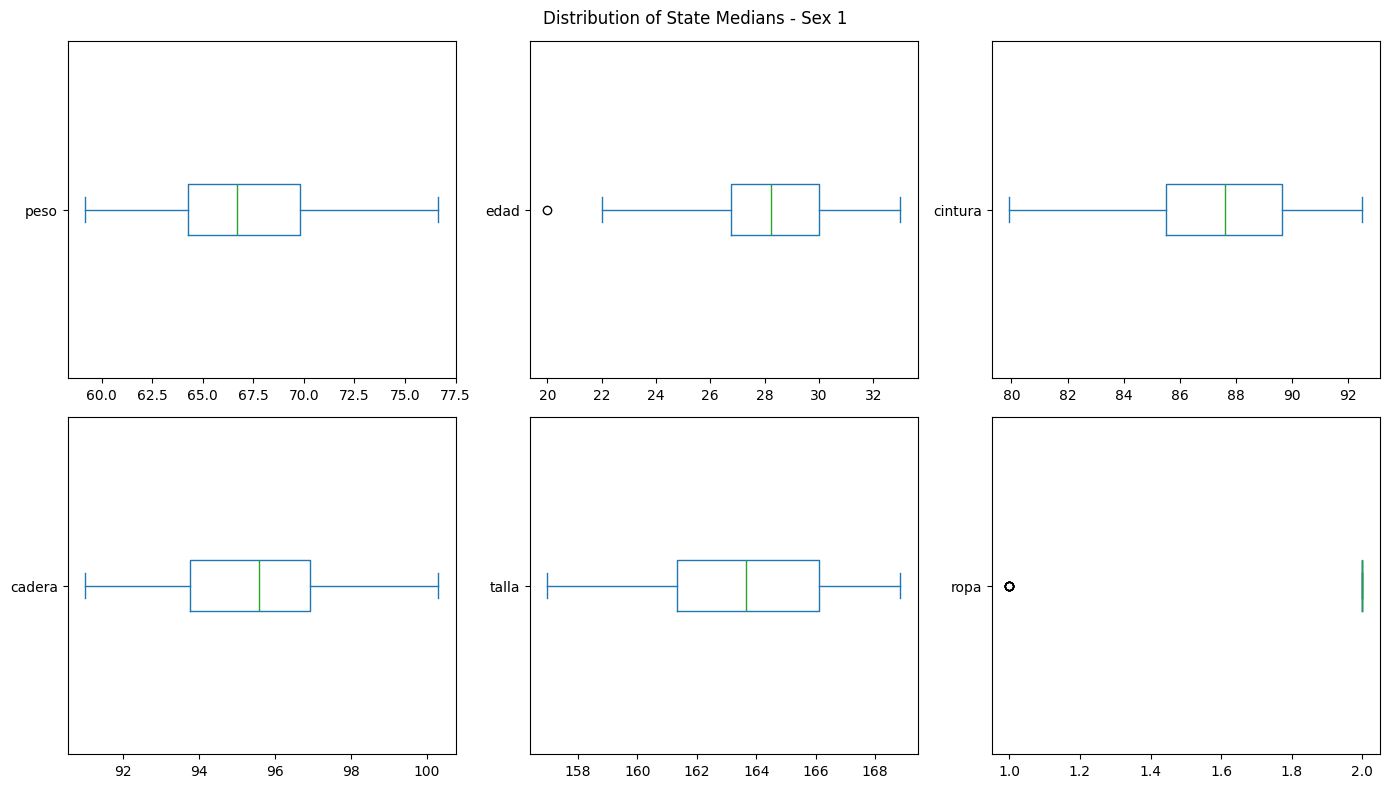

In [60]:
median_sex1[measurement_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    vert=False,
    sharex=False,
    sharey=False
)

plt.suptitle('Distribution of State Medians - Sex 1')
plt.tight_layout()
plt.show()

#### Sex 2

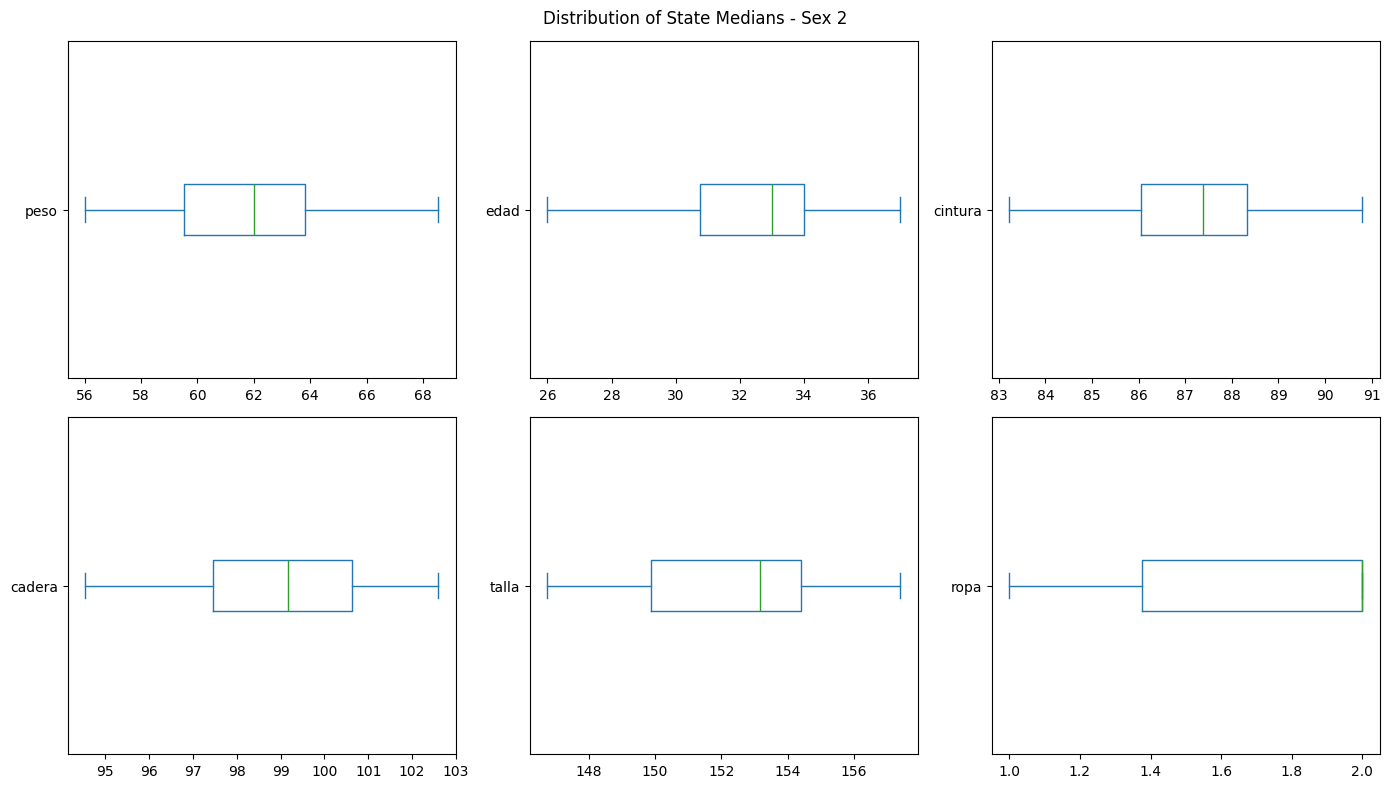

In [61]:
median_sex2[measurement_columns].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    vert=False,
    sharex=False,
    sharey=False
)

plt.suptitle('Distribution of State Medians - Sex 2')
plt.tight_layout()
plt.show()

### Line plot of median measurements

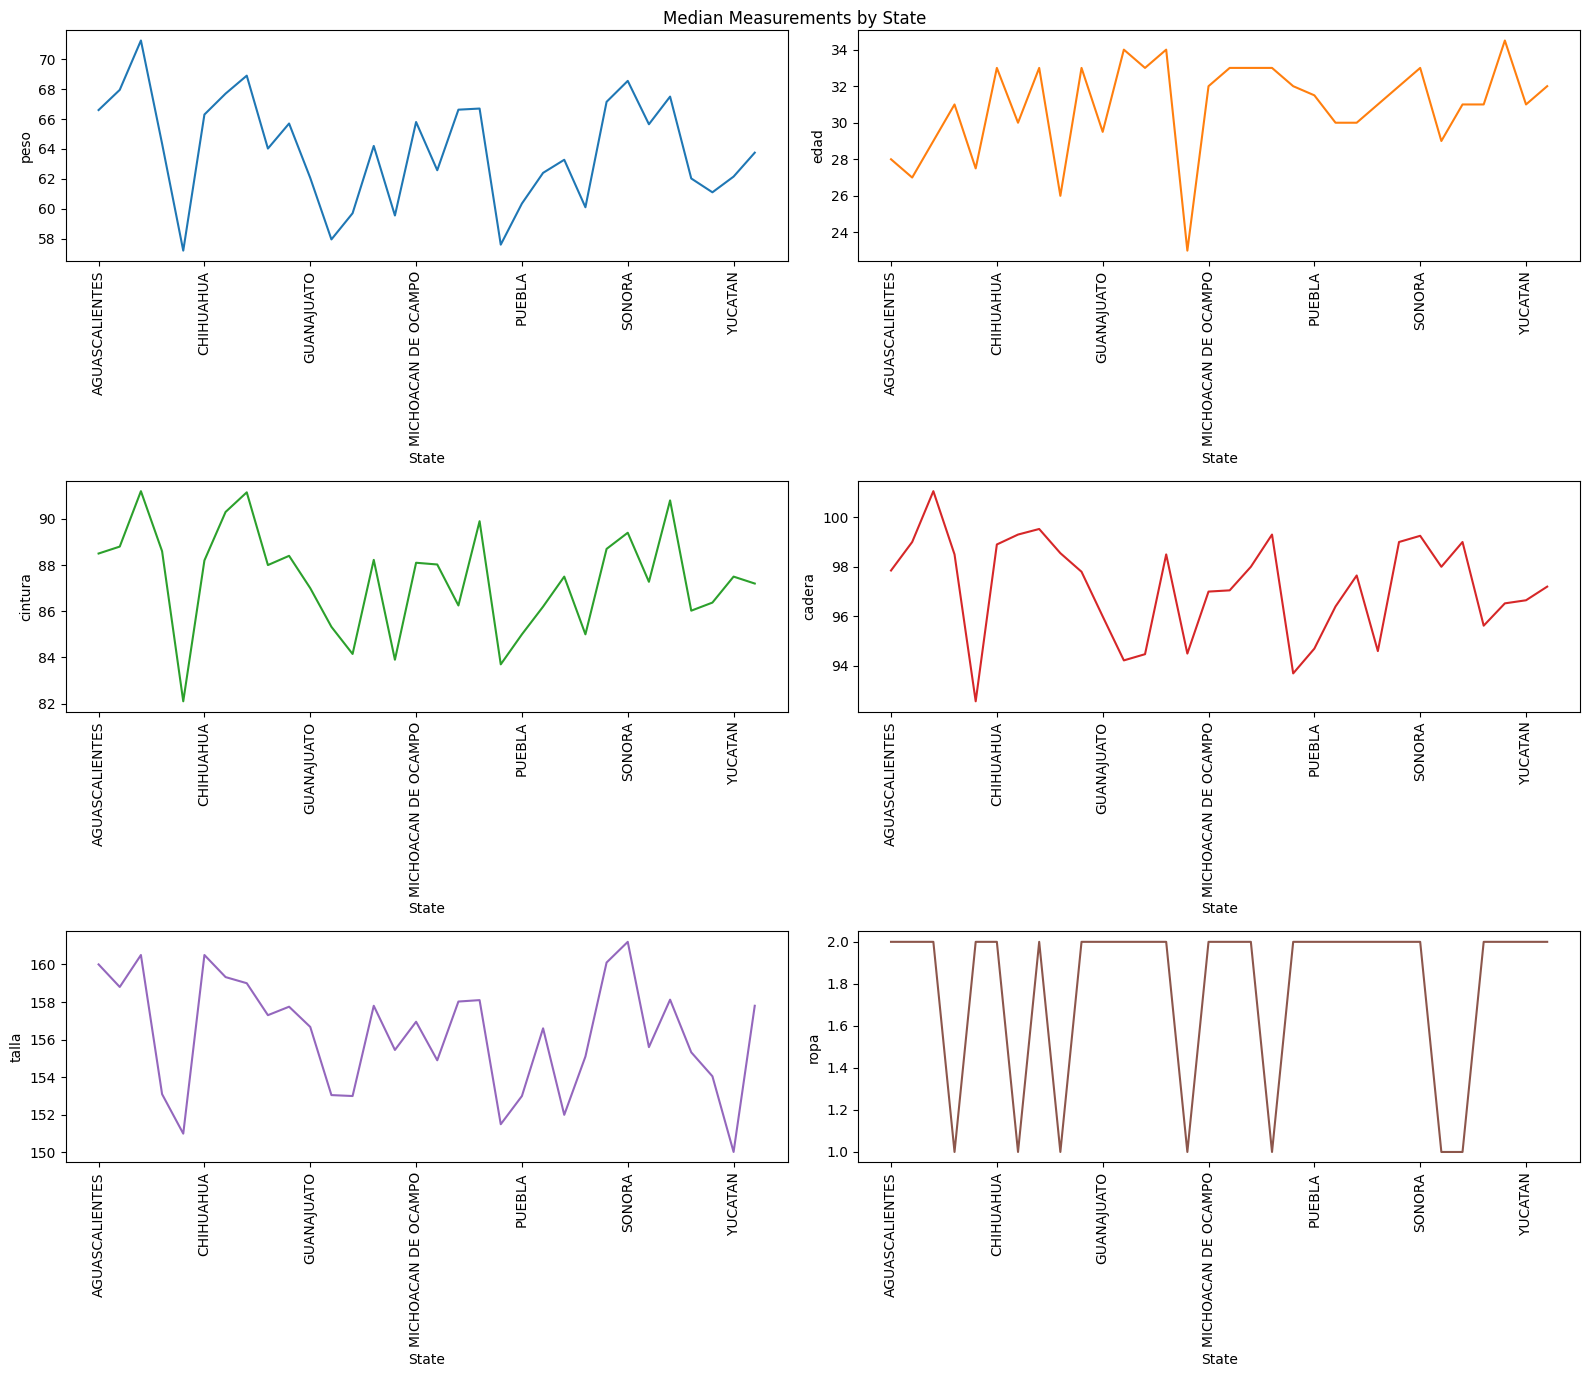

In [62]:
axes = median_overall_table[measurement_columns].plot(
    kind='line',
    subplots=True,
    layout=(3, 2),
    figsize=(16, 14),
    rot=90,
    legend=False,
    sharex=False
)

for ax, column in zip(axes.flatten(), measurement_columns):
    ax.set_xlabel('State')
    ax.set_ylabel(column)

plt.suptitle('Median Measurements by State')
plt.tight_layout()
plt.show()

#### Sex 1

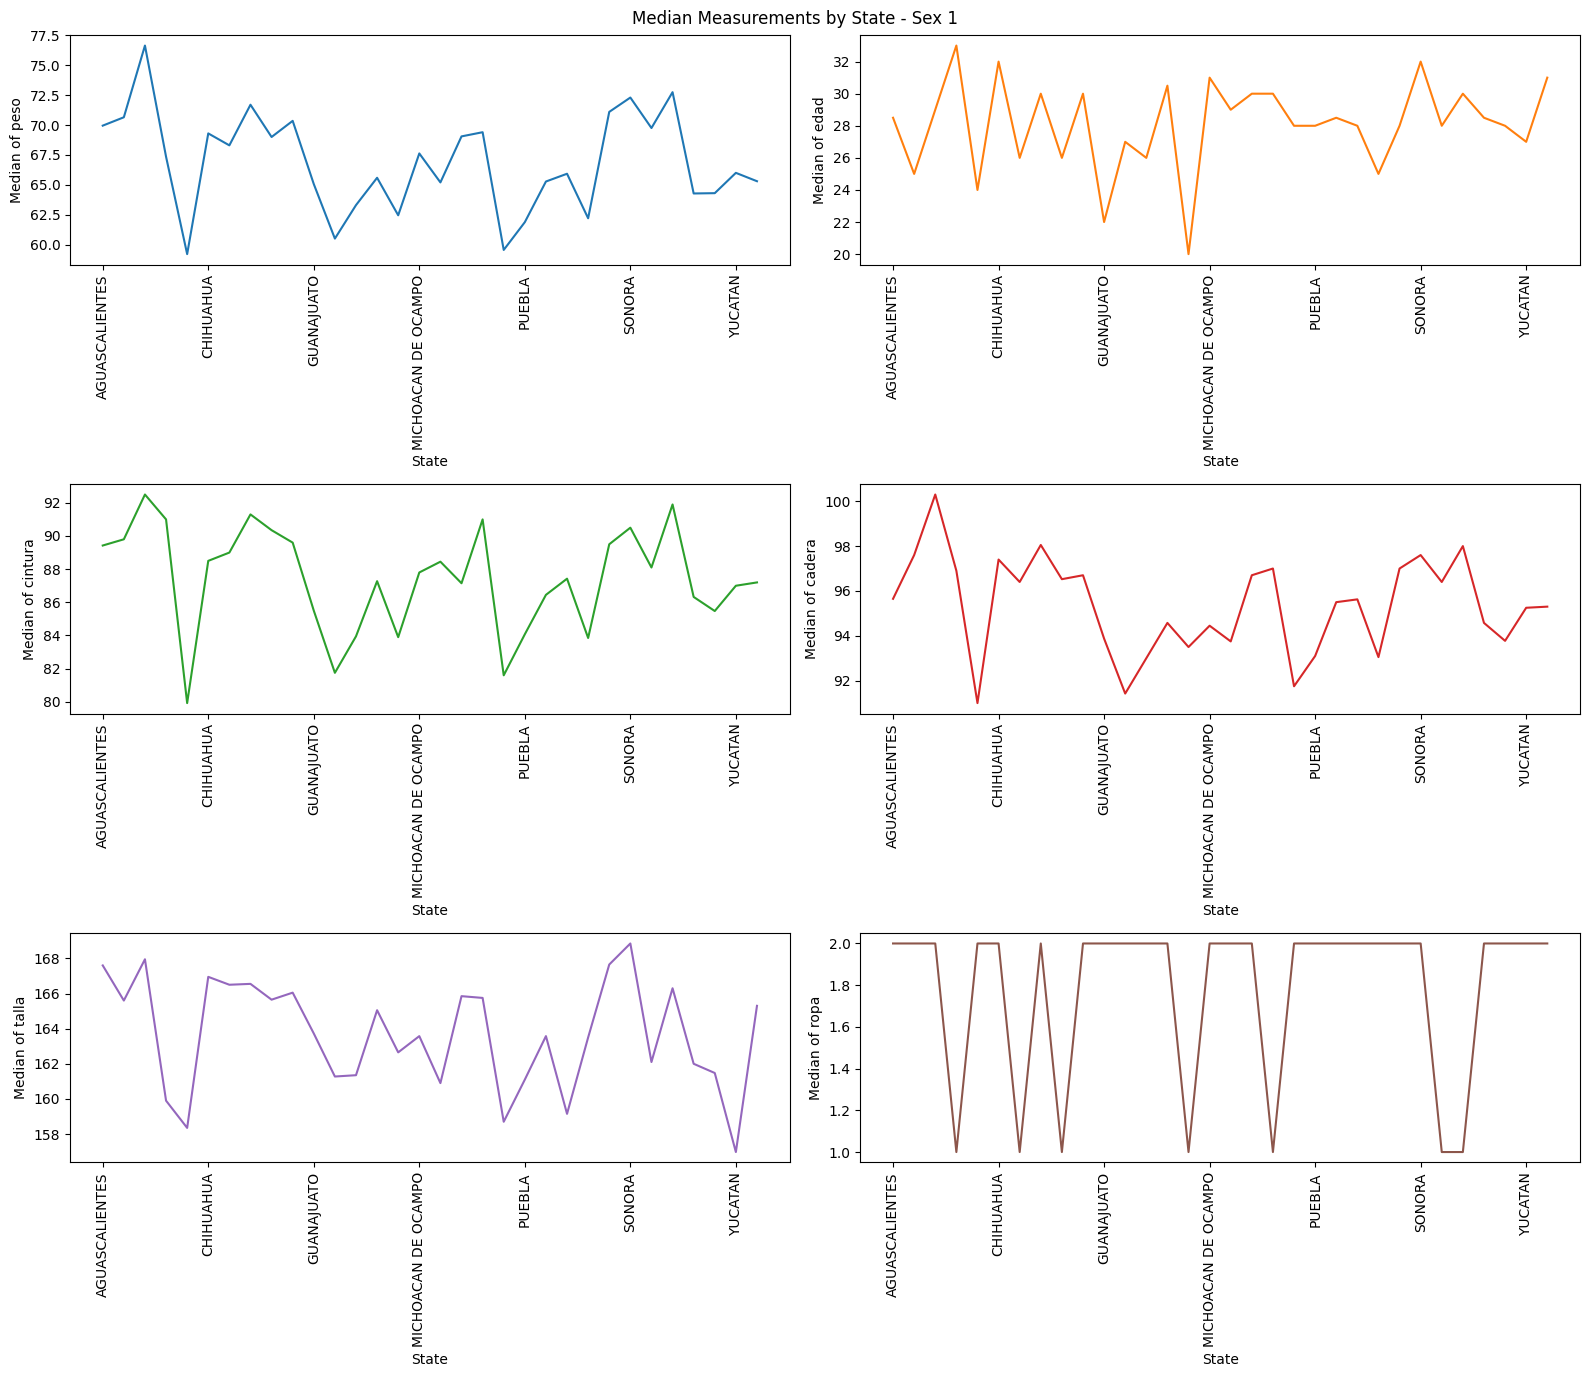

In [63]:
axes = median_sex1[measurement_columns].plot(
    kind='line',
    subplots=True,
    layout=(3, 2),
    figsize=(16, 14),
    rot=90,
    legend=False,
    sharex=False,
    sharey=False
)

for ax, column in zip(axes.flatten(), measurement_columns):
    ax.set_xlabel('State')
    ax.set_ylabel('Median of ' + column)

plt.suptitle('Median Measurements by State - Sex 1')
plt.tight_layout()
plt.show()

#### Sex 2

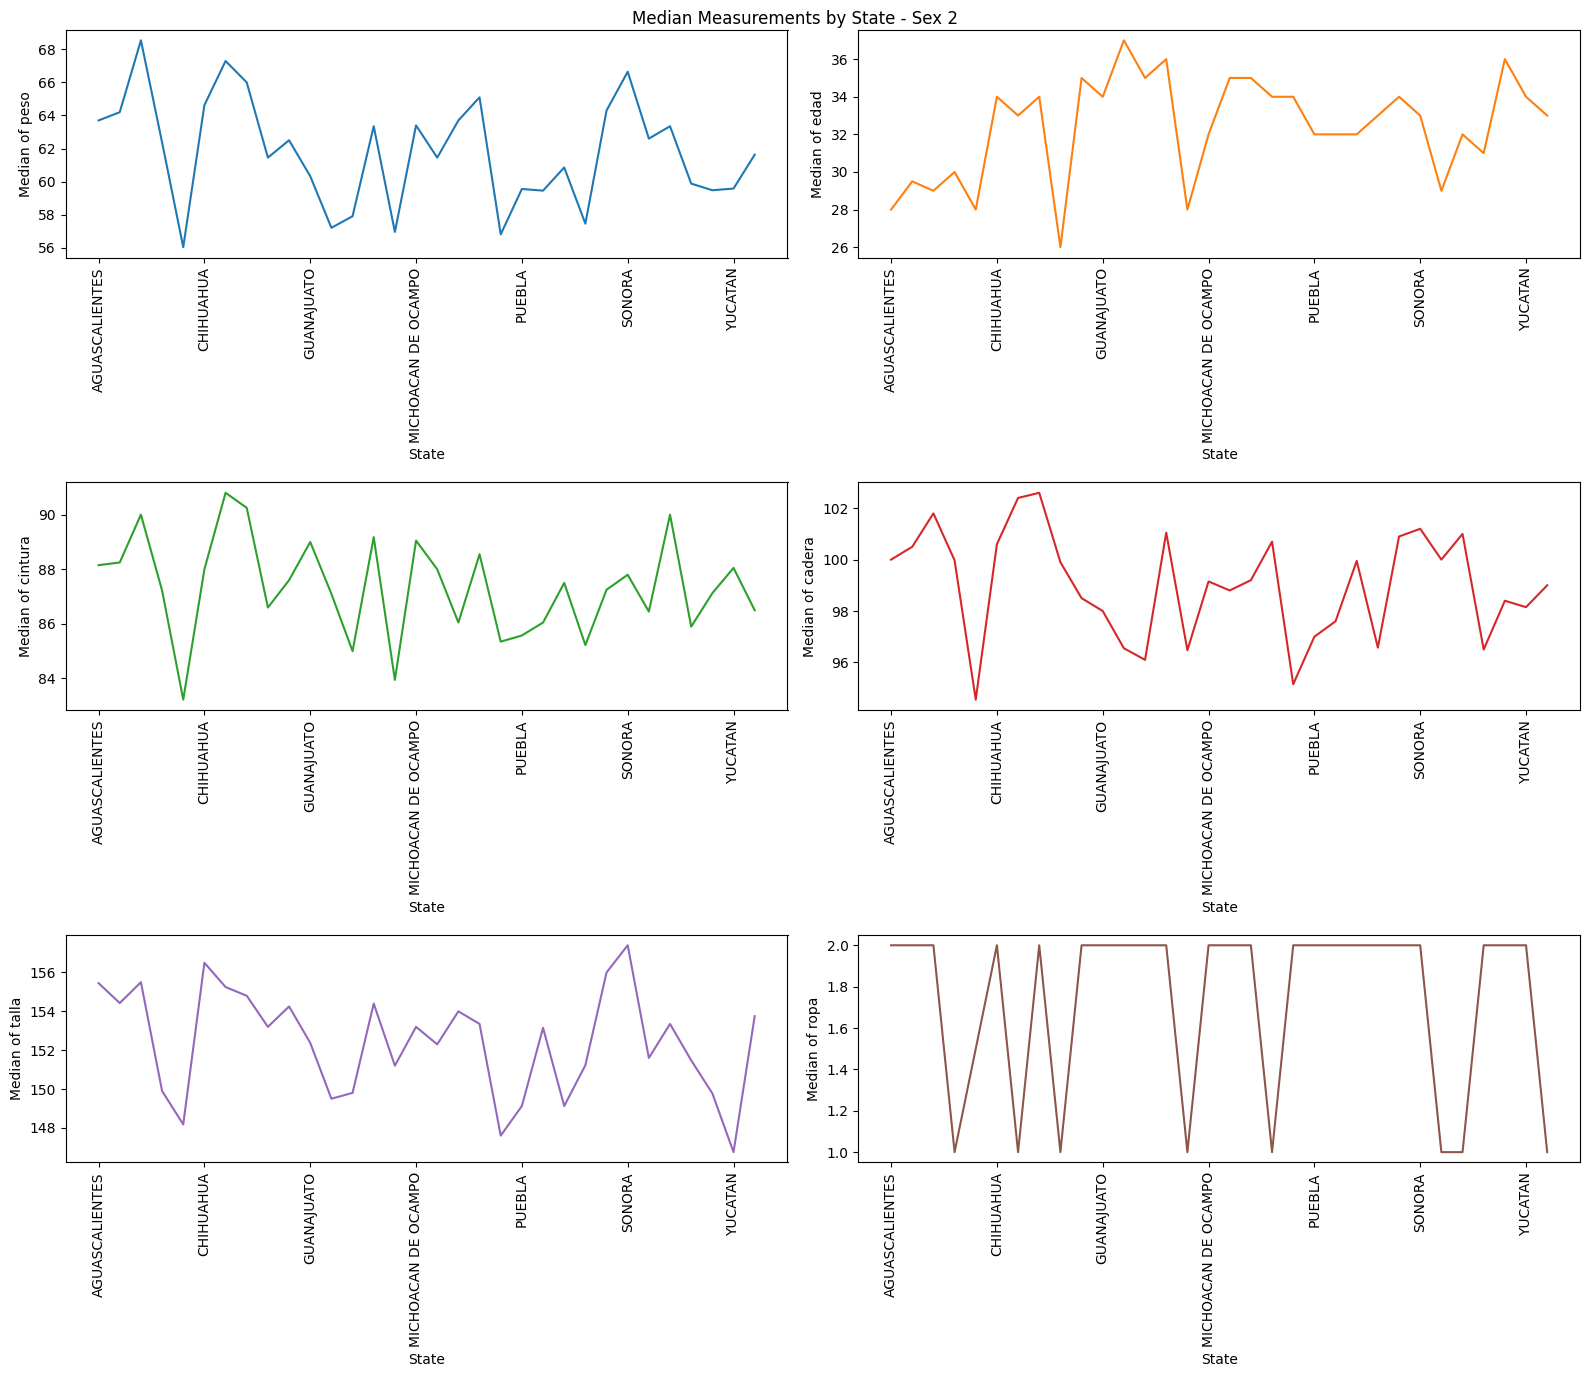

In [64]:
axes = median_sex2[measurement_columns].plot(
    kind='line',
    subplots=True,
    layout=(3, 2),
    figsize=(16, 14),
    rot=90,
    legend=False,
    sharex=False,
    sharey=False
)

for ax, column in zip(axes.flatten(), measurement_columns):
    ax.set_xlabel('State')
    ax.set_ylabel('Median of ' + column)

plt.suptitle('Median Measurements by State - Sex 2')
plt.tight_layout()
plt.show()

### Bar plot for sum of measurements

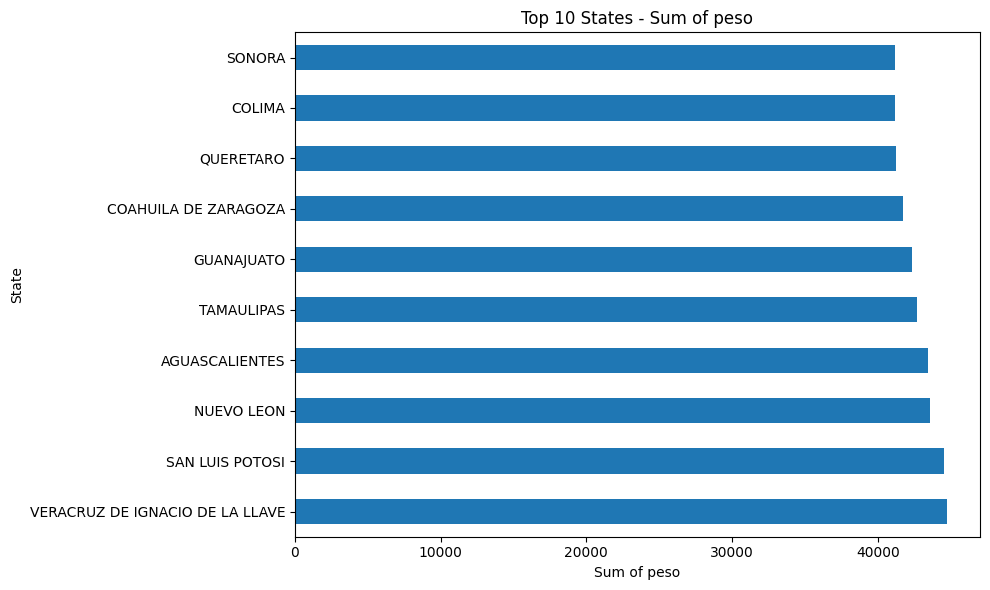

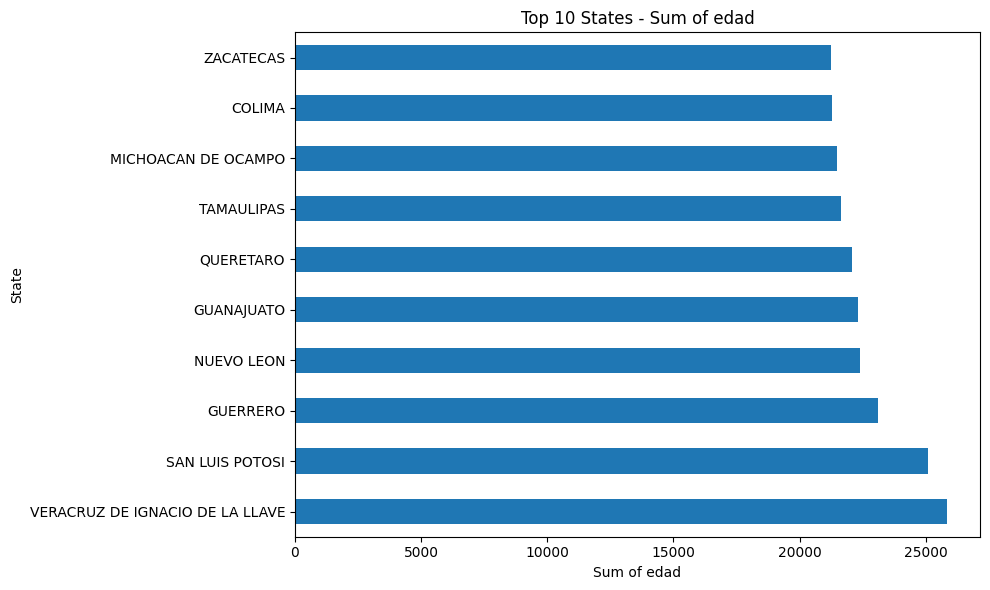

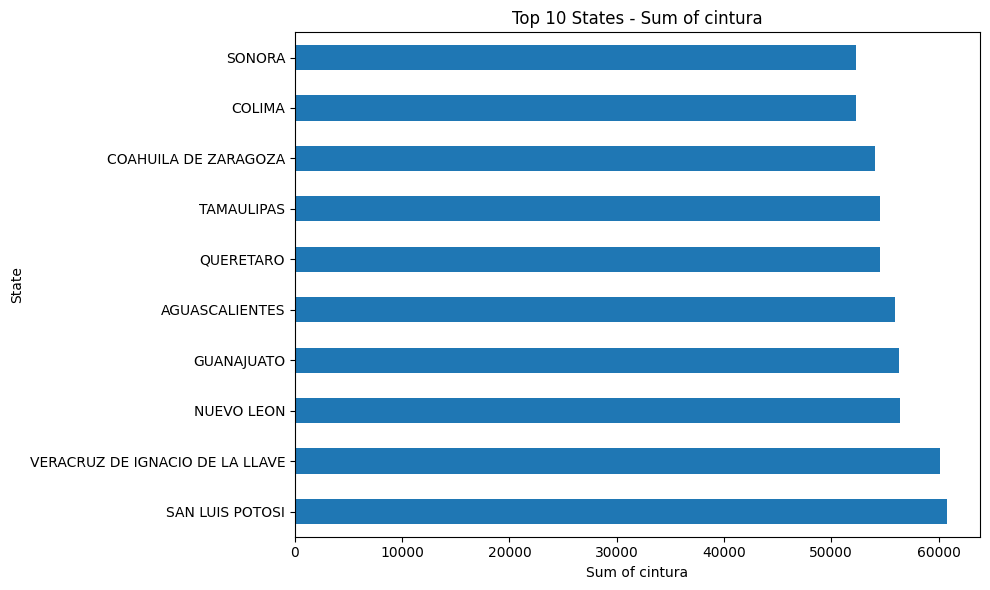

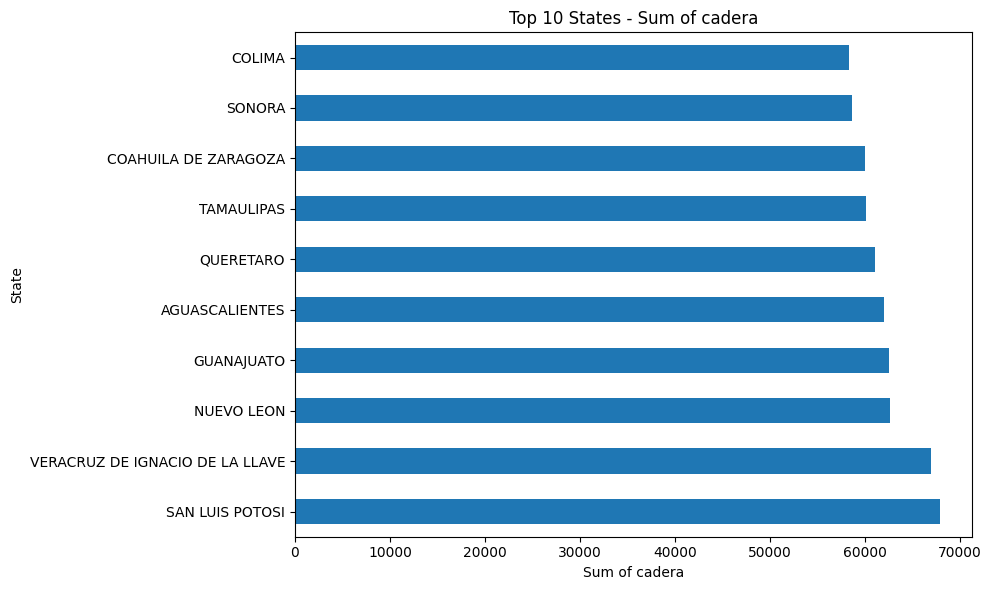

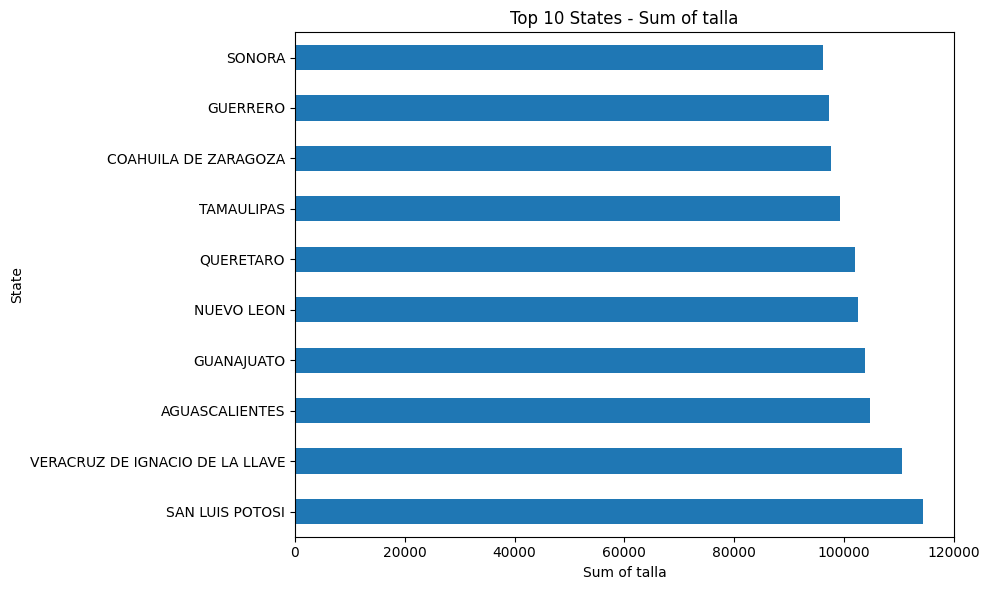

In [ ]:
for column in measurement_columns:
    top10 = sum_overall_table[column].nlargest(10)

    top10.sort_values(ascending=False).plot(
        kind='barh',
        figsize=(10, 6)
    )

    plt.title('Top 10 States - Sum of ' + column)
    plt.xlabel('Sum of ' + column)
    plt.ylabel('State')
    plt.tight_layout()
    plt.show()

#### Sex 1

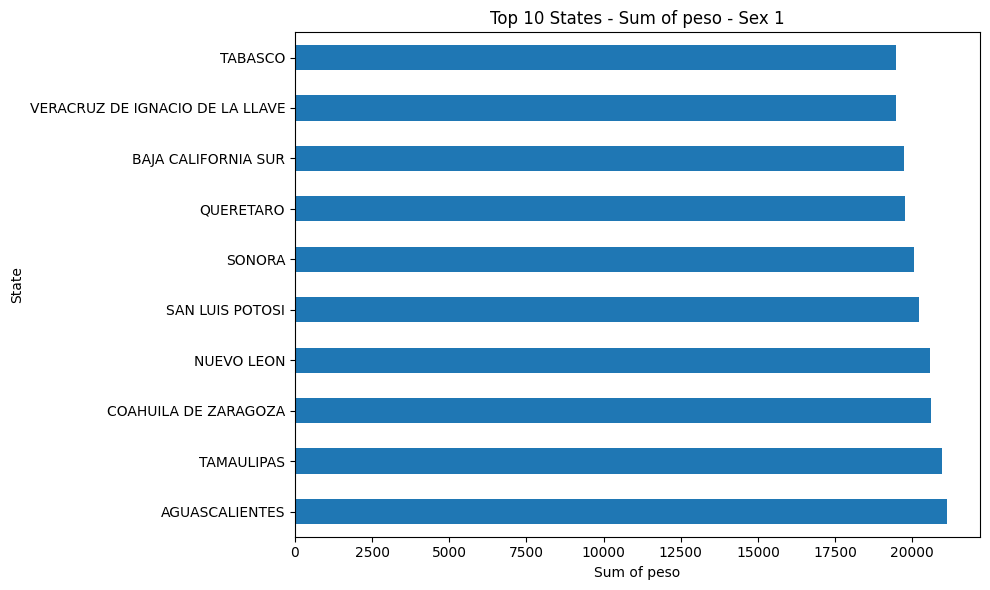

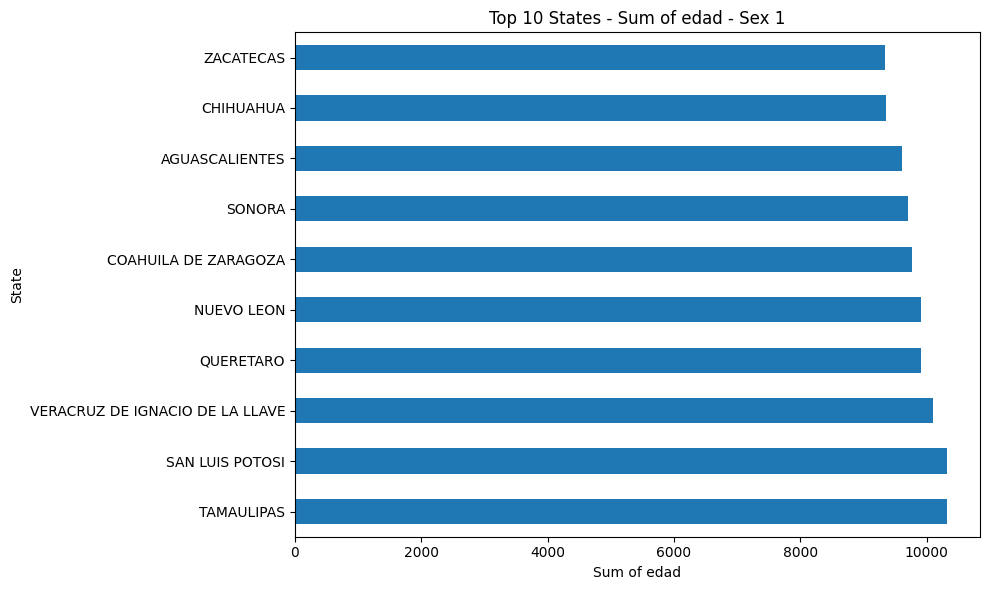

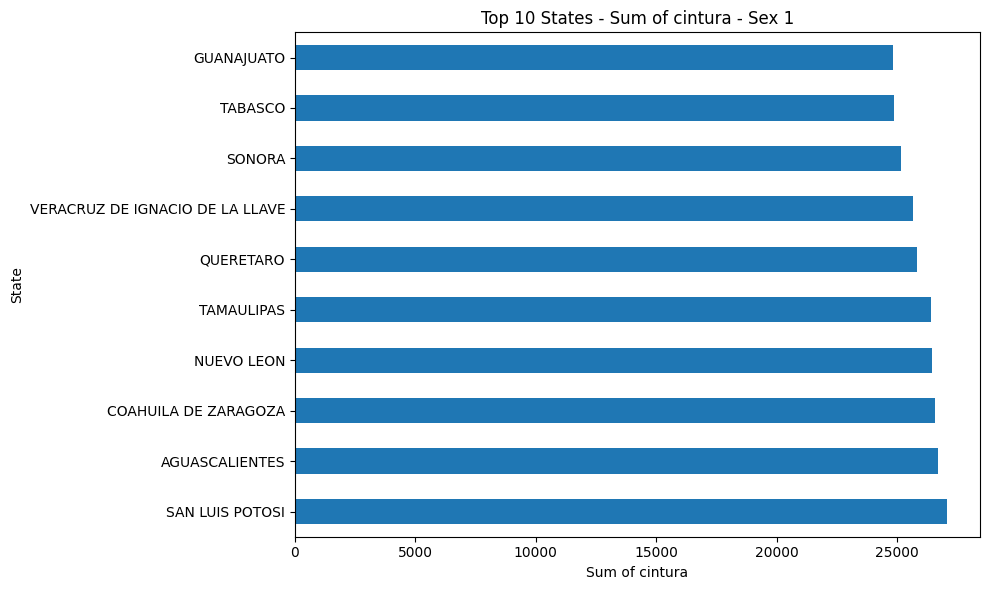

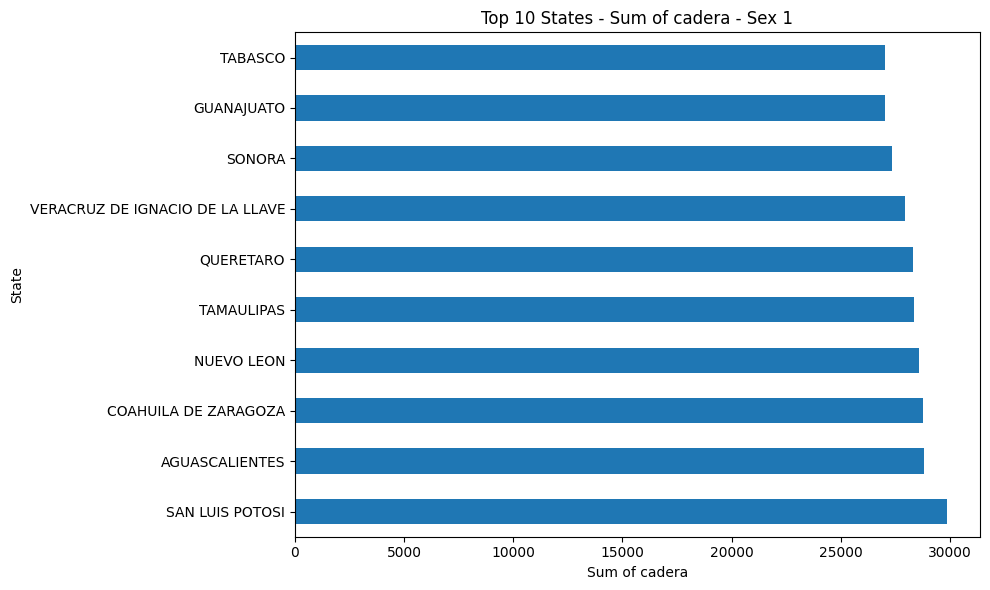

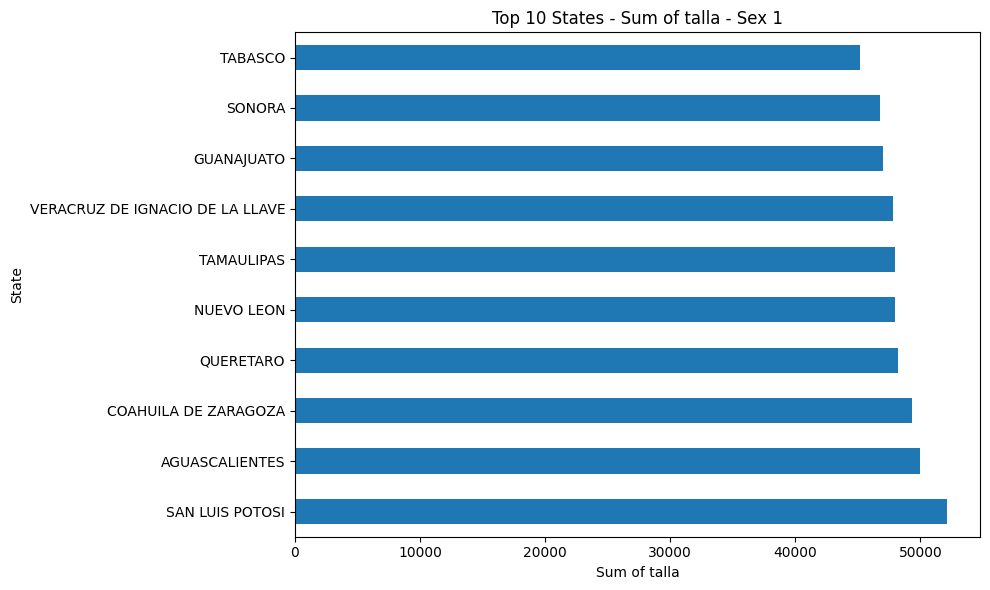

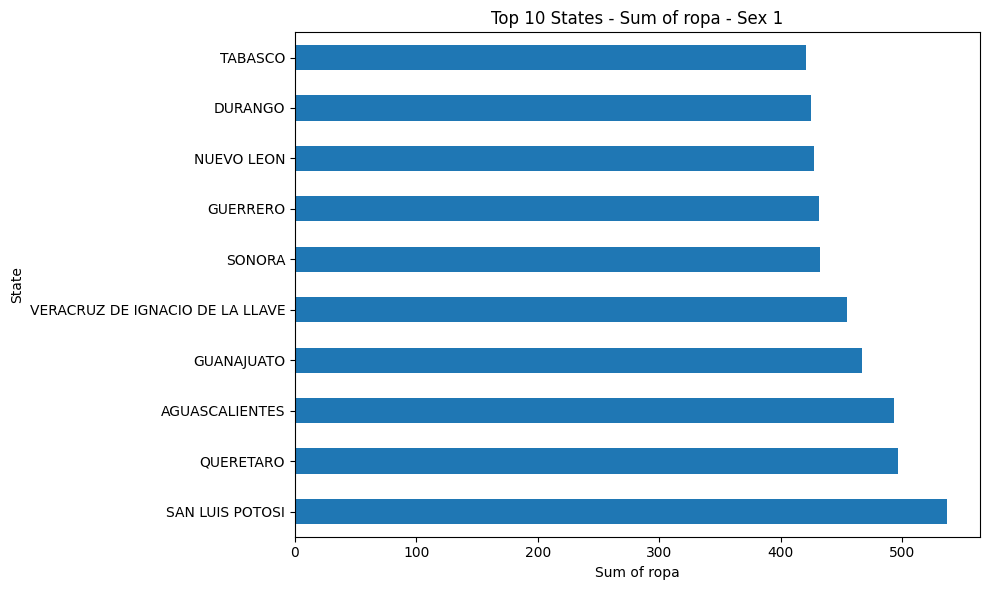

In [33]:
for column in measurement_columns:
    top10 = sum_sex1[column].nlargest(10)

    top10.sort_values(ascending=False).plot(
        kind='barh',
        figsize=(10, 6)
    )

    plt.title('Top 10 States - Sum of ' + column + ' - Sex 1')
    plt.xlabel('Sum of ' + column)
    plt.ylabel('State')
    plt.tight_layout()
    plt.show()

#### Sex 2

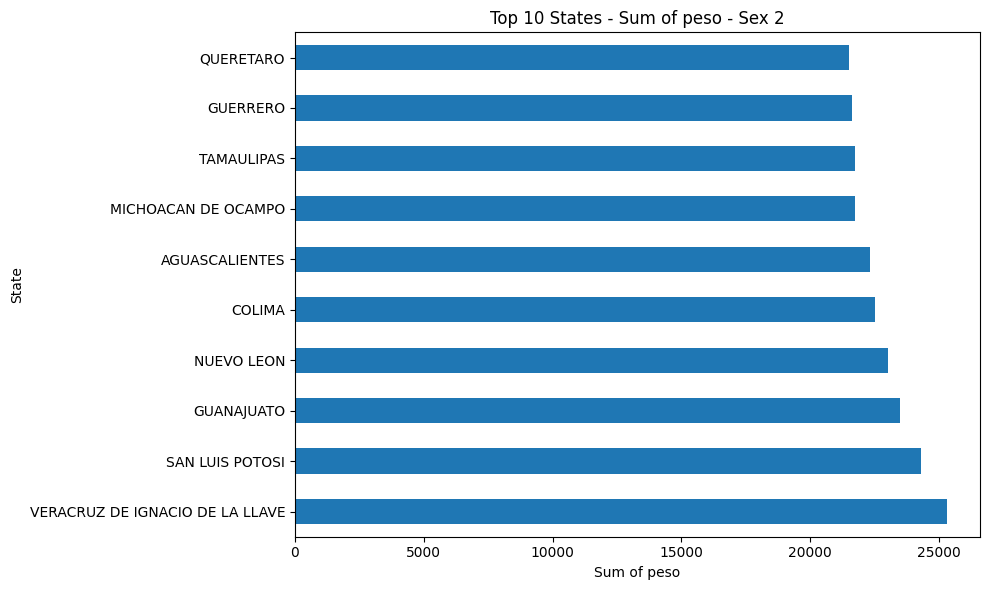

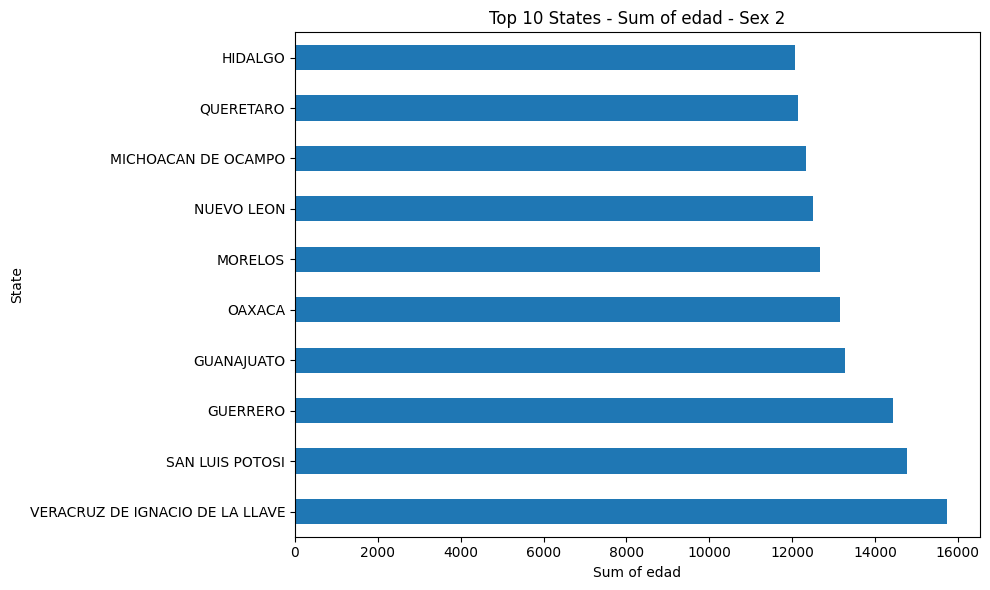

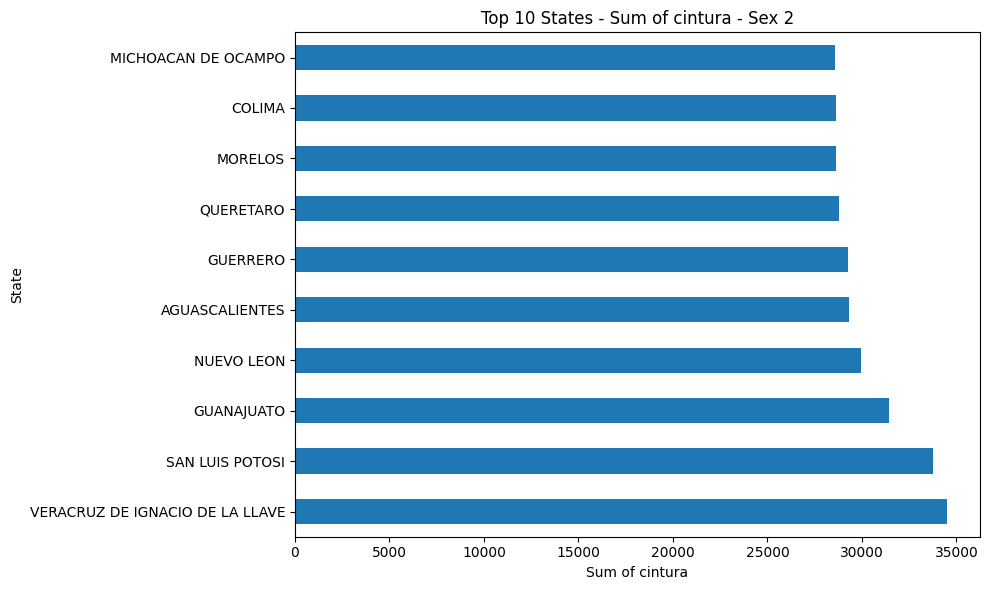

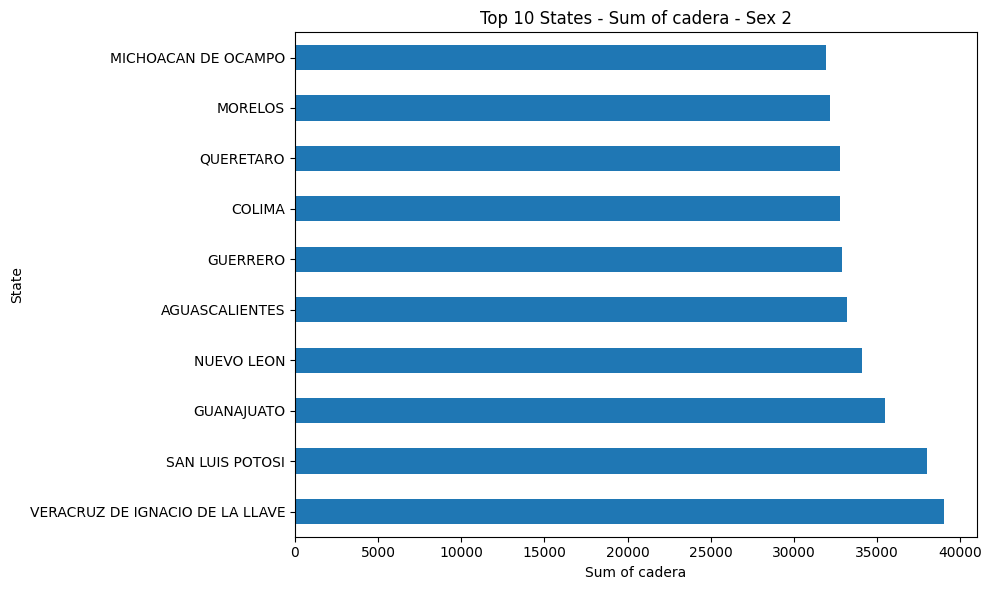

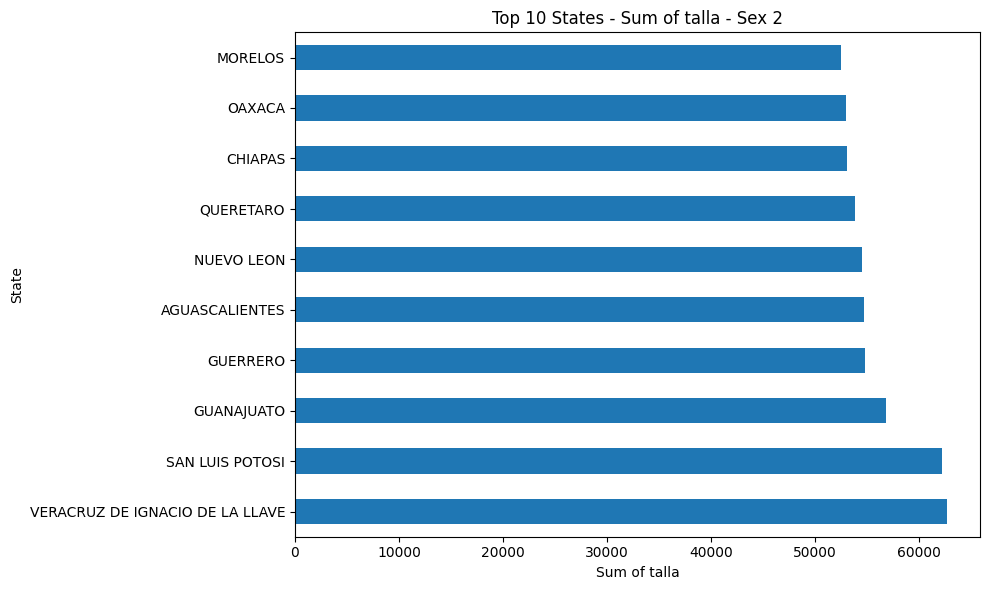

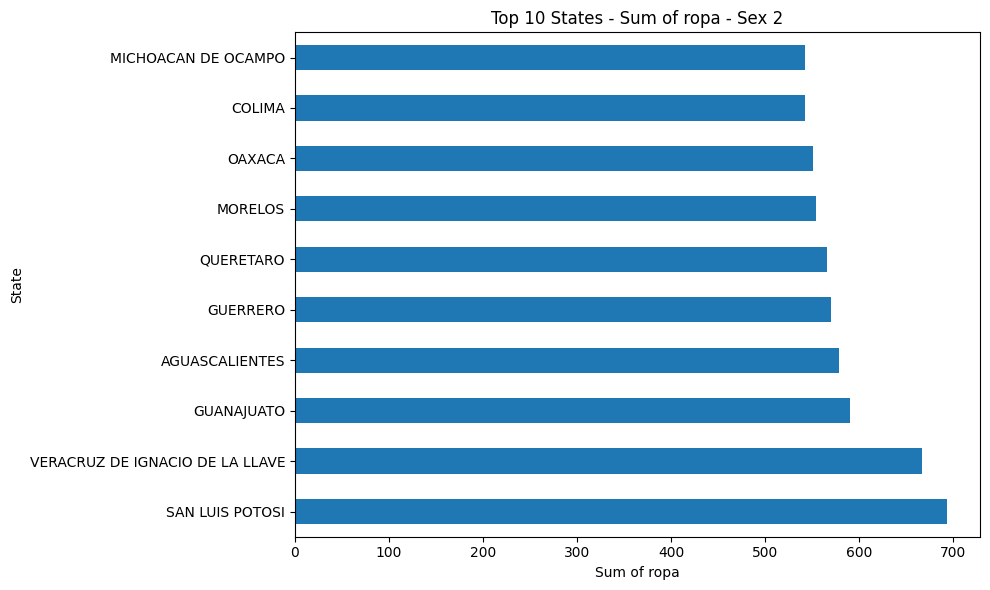

In [34]:
for column in measurement_columns:
    top10 = sum_sex2[column].nlargest(10)

    top10.sort_values(ascending=False).plot(
        kind='barh',
        figsize=(10, 6)
    )

    plt.title('Top 10 States - Sum of ' + column + ' - Sex 2')
    plt.xlabel('Sum of ' + column)
    plt.ylabel('State')
    plt.tight_layout()
    plt.show()

### Histograms

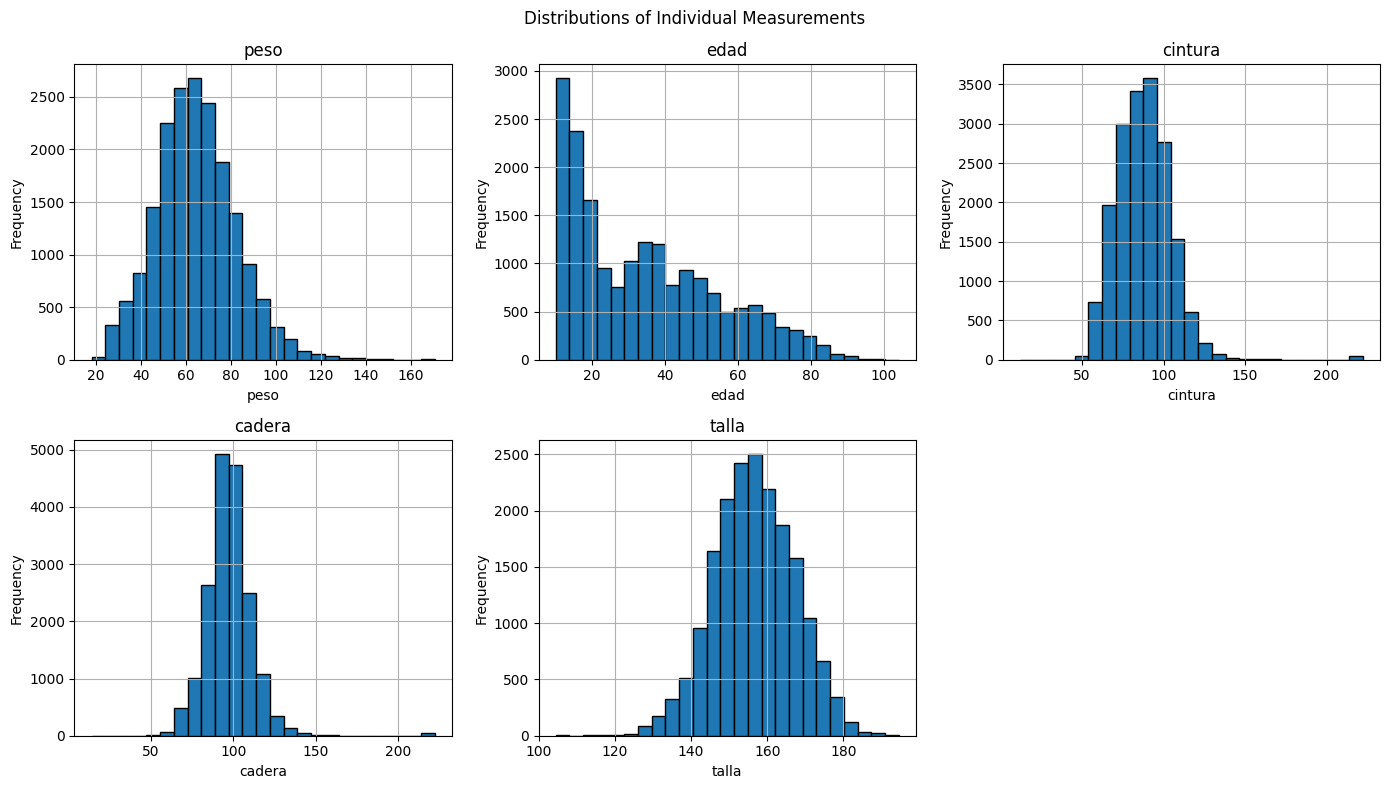

In [ ]:
axes = ndf[measurement_columns].hist(
    bins=25,
    figsize=(14, 8),
    layout=(2, 3),
    edgecolor='black'
)

for ax in axes.flatten():
    if ax.get_visible():
        ax.set_xlabel(ax.get_title())
        ax.set_ylabel('Frequency')

plt.suptitle('Distributions of Individual Measurements')
plt.tight_layout()
plt.show()

#### Sex 1

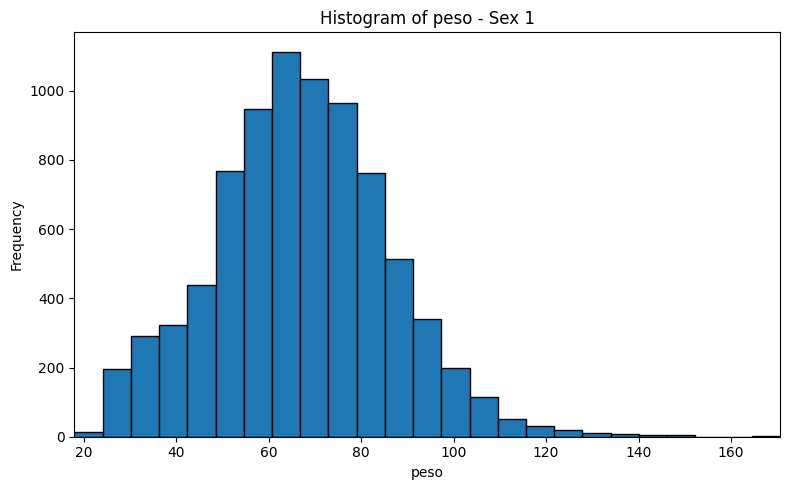

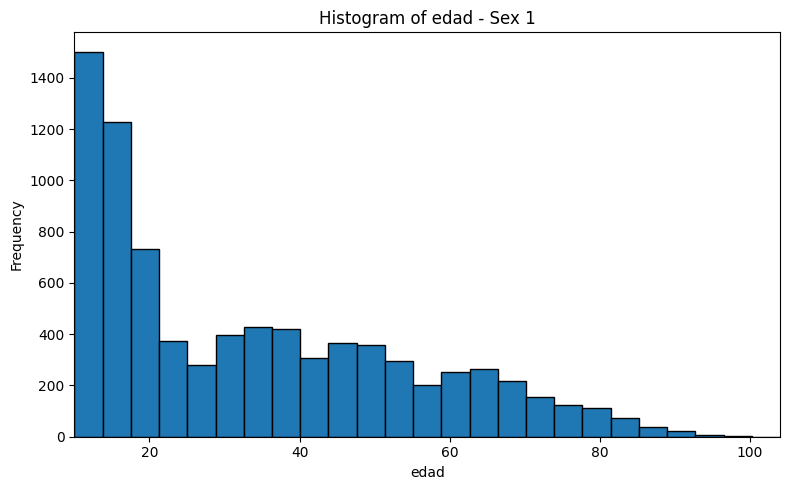

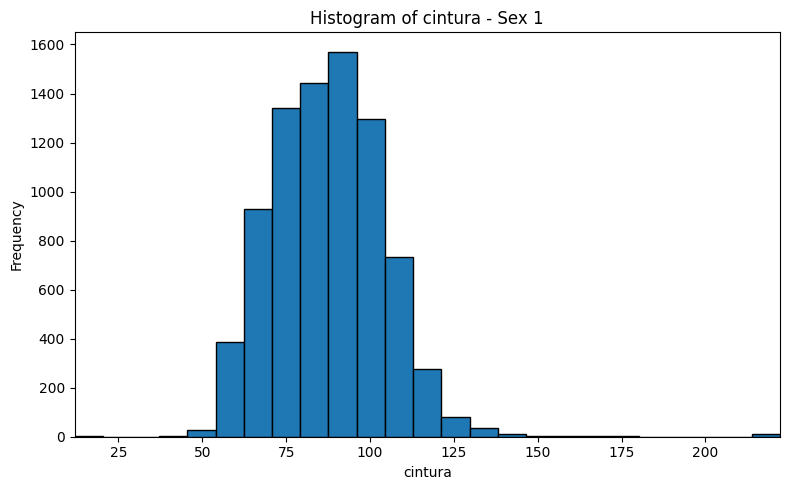

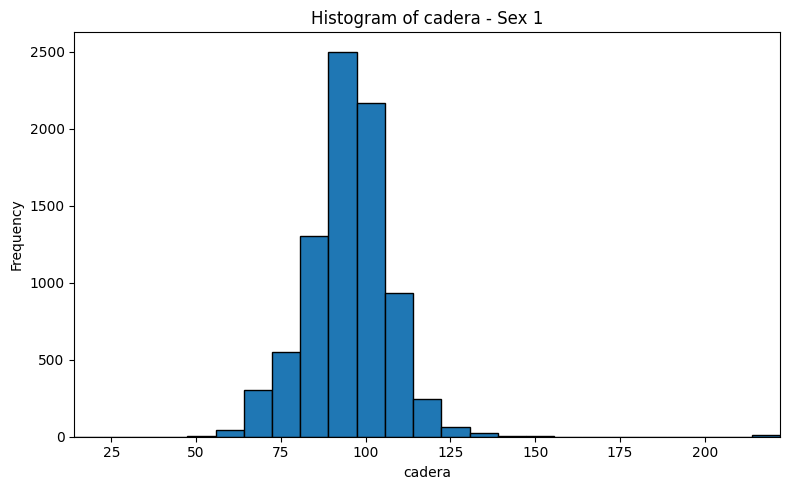

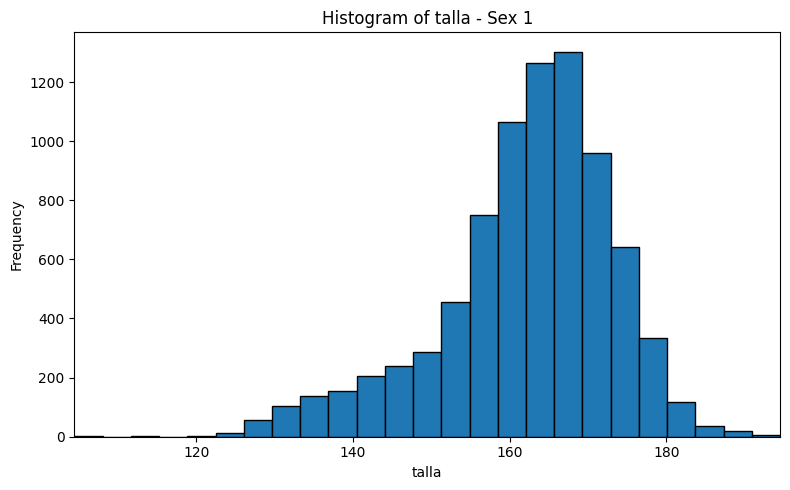

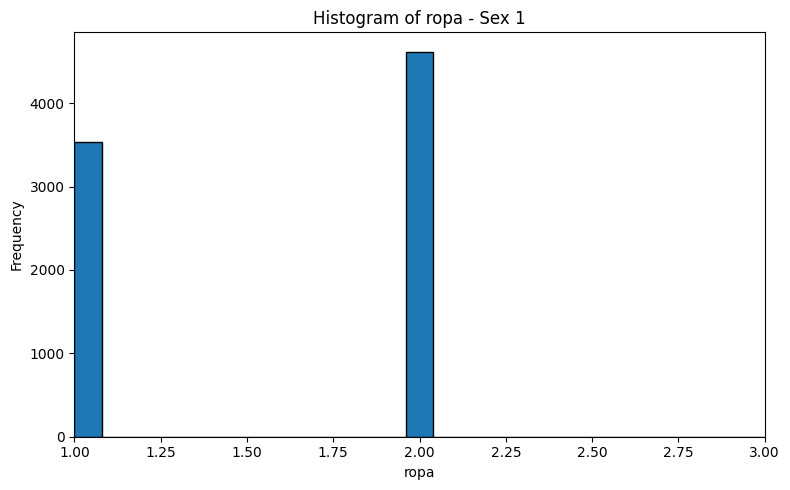

In [35]:
for column in measurement_columns:
    bins = np.histogram_bin_edges(
        ndf[column].dropna(),
        bins=25
    )


    plt.figure(figsize=(8, 5))

    plt.hist(
        sex_1[column].dropna(),
        bins=bins,
        edgecolor='black'
    )

    plt.title('Histogram of ' + column + ' - Sex 1')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.xlim(bins[0], bins[-1])
    plt.tight_layout()
    plt.show()



#### Sex 2

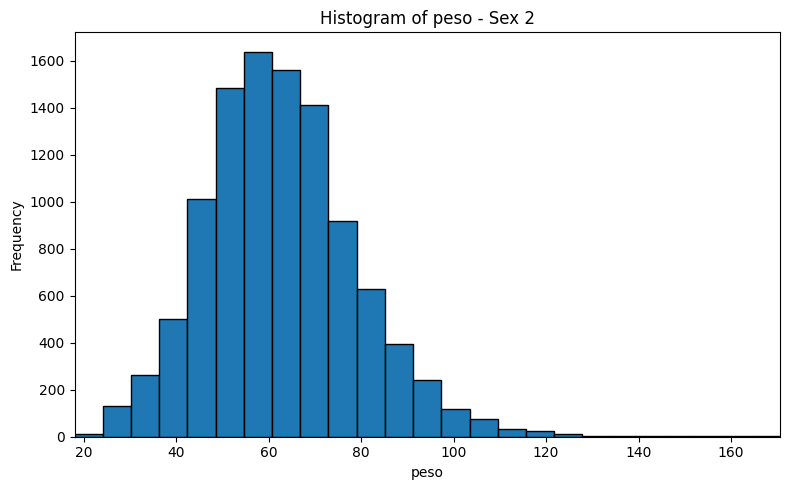

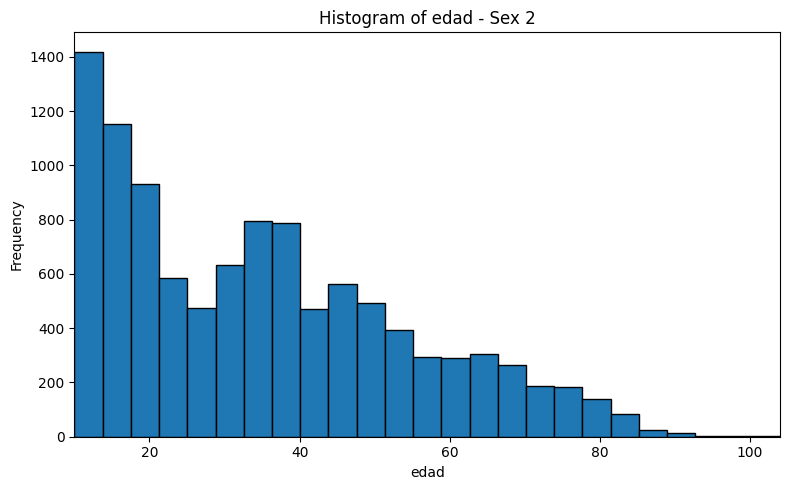

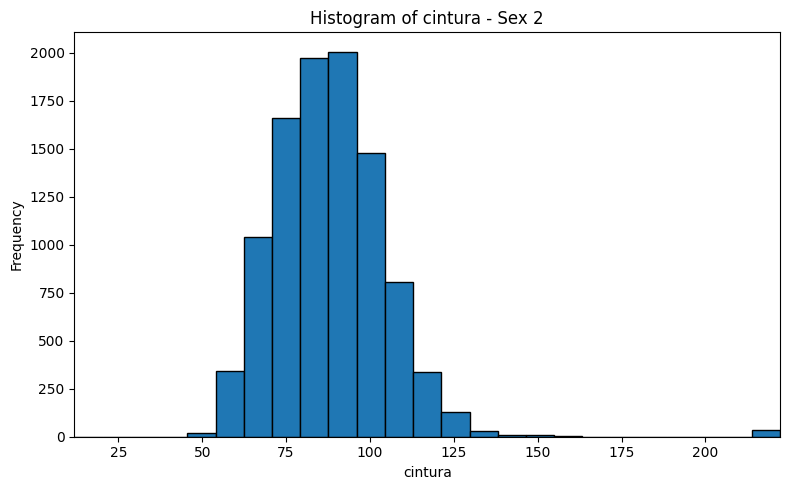

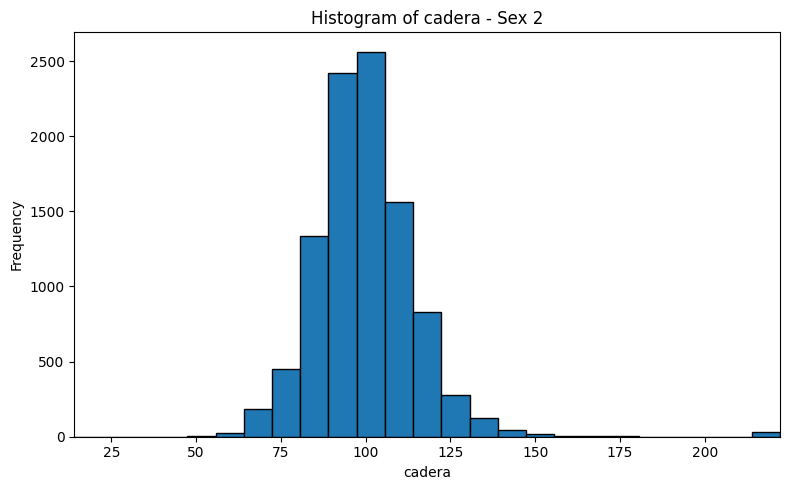

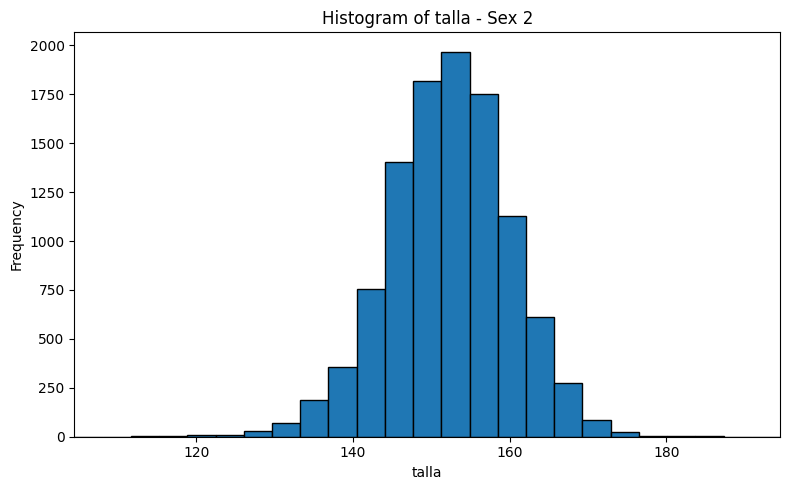

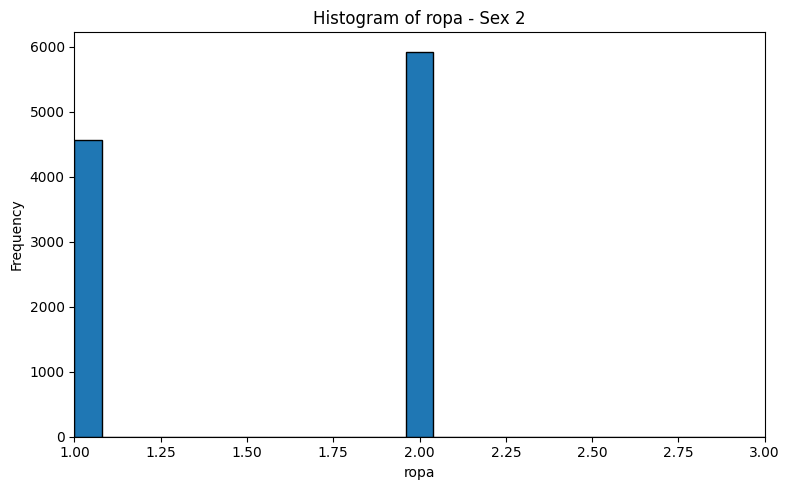

In [37]:
for column in measurement_columns:
    bins = np.histogram_bin_edges(
        ndf[column].dropna(),
        bins=25
    )
    plt.figure(figsize=(8, 5))

    plt.hist(
        sex_2[column].dropna(),
        bins=bins,
        edgecolor='black'
    )

    plt.title('Histogram of ' + column + ' - Sex 2')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.xlim(bins[0], bins[-1])
    plt.tight_layout()
    plt.show()

## Quiz questions


### 1. Waist Boxplot


In [ ]:
waist = ndf['cintura'].dropna()

waist.describe()

,cintura
count,18032.000000
mean,87.778529
std,16.950062
min,11.900000
25%,76.000000
50%,87.250000
75%,98.000000
max,222.220000


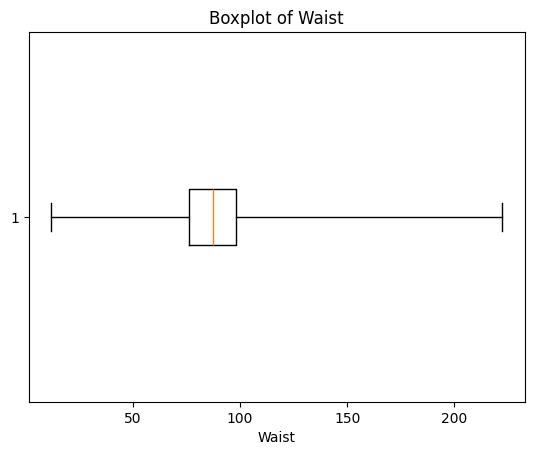

In [ ]:
plt.boxplot(waist, vert=False, whis=(0, 100))
plt.title('Boxplot of Waist')
plt.xlabel('Waist')
plt.show()

In [ ]:
print('The boxplot for "cintura" is \n:  option 4')

The boxplot for "cintura" is 
:  option 4


### 2. Boxplot of age median for sex 2

In [ ]:
median_age_table = ndf.pivot_table(
    values = 'edad',
    index = 'desc_ent',
    columns = 'sexo',
    aggfunc = 'median'
)
median_age_table

sexo,1,2
desc_ent,,
AGUASCALIENTES,28.5,28.0
BAJA CALIFORNIA,25.0,29.5
BAJA CALIFORNIA SUR,29.0,29.0
CAMPECHE,33.0,30.0
CHIAPAS,24.0,28.0
CHIHUAHUA,32.0,34.0
COAHUILA DE ZARAGOZA,26.0,33.0
COLIMA,30.0,34.0
DISTRITO FEDERAL,26.0,26.0


In [ ]:
median_sex2_age = median_age_table.loc[:, 2]
median_sex2_age

,2
desc_ent,
AGUASCALIENTES,28.0
BAJA CALIFORNIA,29.5
BAJA CALIFORNIA SUR,29.0
CAMPECHE,30.0
CHIAPAS,28.0
CHIHUAHUA,34.0
COAHUILA DE ZARAGOZA,33.0
COLIMA,34.0
DISTRITO FEDERAL,26.0


In [ ]:
median_sex2_age.describe()

,2
count,32.000000
mean,32.421875
std,2.738935
min,26.000000
25%,30.750000
50%,33.000000
75%,34.000000
max,37.000000


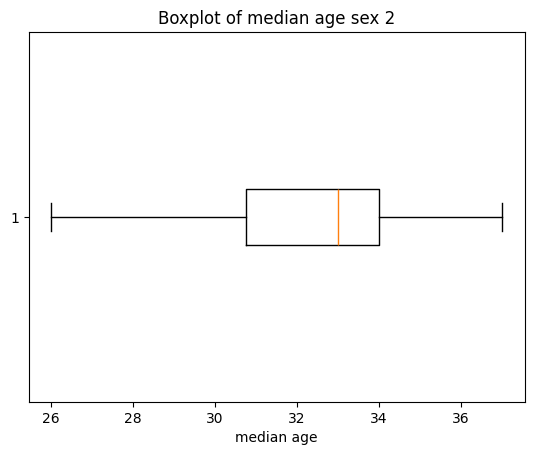

In [ ]:
plt.boxplot(median_sex2_age, vert=False, whis=(0, 100))
plt.title('Boxplot of median age sex 2')
plt.xlabel('median age')
plt.show()

In [ ]:
print('The boxplot for the median age for sex 2 is \n: B ')

The boxplot for the median age for sex 2 is 
: B 


### 3. Line plot of hip sex 1

In [ ]:
hip = ndf['cadera'].dropna()

hip.describe()

,cadera
count,18032.000000
mean,97.733534
std,14.266419
min,14.100000
25%,89.750000
50%,97.150000
75%,105.000000
max,222.220000


In [ ]:
hip_table = ndf.pivot_table(
    values = 'cadera',
    index = 'desc_ent',
    columns = 'sexo',
    aggfunc= 'median'

)
hip_table

sexo,1,2
desc_ent,,
AGUASCALIENTES,95.650,100.000
BAJA CALIFORNIA,97.600,100.500
BAJA CALIFORNIA SUR,100.300,101.800
CAMPECHE,96.900,99.975
CHIAPAS,91.000,94.550
CHIHUAHUA,97.400,100.600
COAHUILA DE ZARAGOZA,96.400,102.400
COLIMA,98.050,102.600
DISTRITO FEDERAL,96.525,99.900


In [ ]:
sex1_hip_median = hip_table.loc[:, 1]
sex1_hip_median

,1
desc_ent,
AGUASCALIENTES,95.650
BAJA CALIFORNIA,97.600
BAJA CALIFORNIA SUR,100.300
CAMPECHE,96.900
CHIAPAS,91.000
CHIHUAHUA,97.400
COAHUILA DE ZARAGOZA,96.400
COLIMA,98.050
DISTRITO FEDERAL,96.525


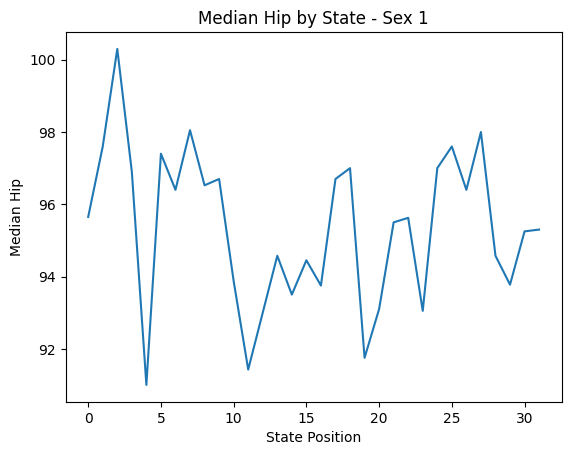

In [ ]:
plt.plot(sex1_hip_median.to_numpy())
plt.title('Median Hip by State - Sex 1')
plt.xlabel('State Position')
plt.ylabel('Median Hip')
plt.show()

In [ ]:
print('The line plot for the median of hip of sex 1 is \n: option A')

The line plot for the median of hip of sex 1 is 
: option A


### 4. Bar plot of  'ropa',  of sex 1

In [ ]:
cloth = ndf['ropa'].dropna()

cloth.describe()

,ropa
count,18640.000000
mean,1.566148
std,0.496051
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,3.000000


In [ ]:
cloth_pivot_sum = ndf.pivot_table(
    values = 'ropa',
    index = 'desc_ent',
    columns = 'sexo',
    aggfunc = 'sum'
)
cloth_pivot_sum

sexo,1,2
desc_ent,,
AGUASCALIENTES,493,579
BAJA CALIFORNIA,402,466
BAJA CALIFORNIA SUR,415,440
CAMPECHE,350,443
CHIAPAS,378,540
CHIHUAHUA,415,526
COAHUILA DE ZARAGOZA,417,439
COLIMA,410,543
DISTRITO FEDERAL,247,298


In [ ]:
sum_sex1_cloth = cloth_pivot_sum.loc[:, 1]
sum_sex1_cloth

,1
desc_ent,
AGUASCALIENTES,493
BAJA CALIFORNIA,402
BAJA CALIFORNIA SUR,415
CAMPECHE,350
CHIAPAS,378
CHIHUAHUA,415
COAHUILA DE ZARAGOZA,417
COLIMA,410
DISTRITO FEDERAL,247


In [ ]:
top_10_states_sum_cloth = sum_sex1_cloth.nlargest(10)

top_10_states_sum_cloth

,1
desc_ent,
SAN LUIS POTOSI,537
QUERETARO,496
AGUASCALIENTES,493
GUANAJUATO,467
VERACRUZ DE IGNACIO DE LA LLAVE,454
SONORA,432
GUERRERO,431
NUEVO LEON,427
DURANGO,425


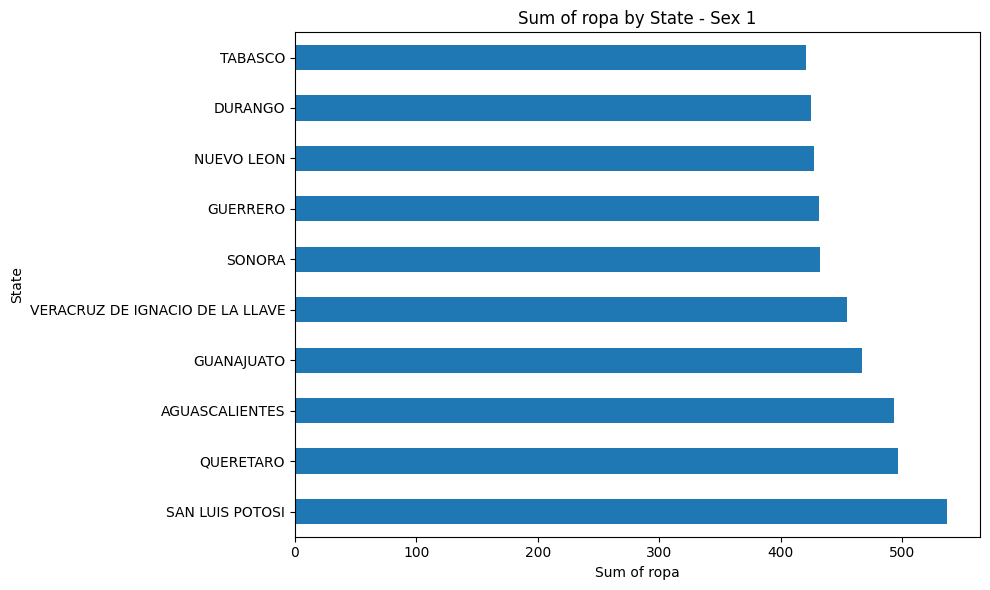

In [ ]:
top_10_states_sum_cloth.sort_values(
    ascending=False
).plot(kind='barh', figsize=(10, 6))

plt.title('Sum of ropa by State - Sex 1')
plt.xlabel('Sum of ropa')
plt.ylabel('State')
plt.tight_layout()
plt.show()

In [ ]:
print('The bar plot for the sum of clothes for sex 1 is \n: option c')

The bar plot for the sum of clothes for sex 1 is 
: option c


### 5. Histogram of "cintura" with bins= 25

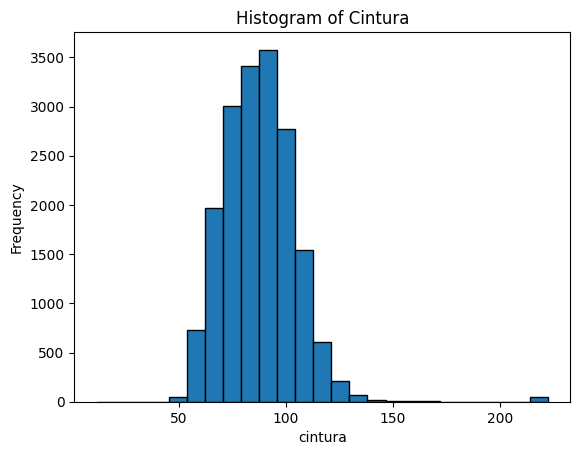

In [ ]:
plt.hist(ndf['cintura'].dropna(), bins=25, edgecolor='black')

plt.title('Histogram of Cintura')
plt.xlabel('cintura')
plt.ylabel('Frequency')
plt.show()

In [ ]:
print('The hsiotogram for "cintura" with 25 bins is : \n option B')

The hsiotogram for "cintura" with 25 bins is : 
 option B


## Distribution diagram, waist vs weight

In [44]:
waist_weight = ndf[['peso', 'cintura']].dropna()
waist_weight.head()

,peso,cintura
0,73.70,98.7
1,35.65,64.0
2,54.80,67.6
3,33.40,60.6
4,97.95,113.0


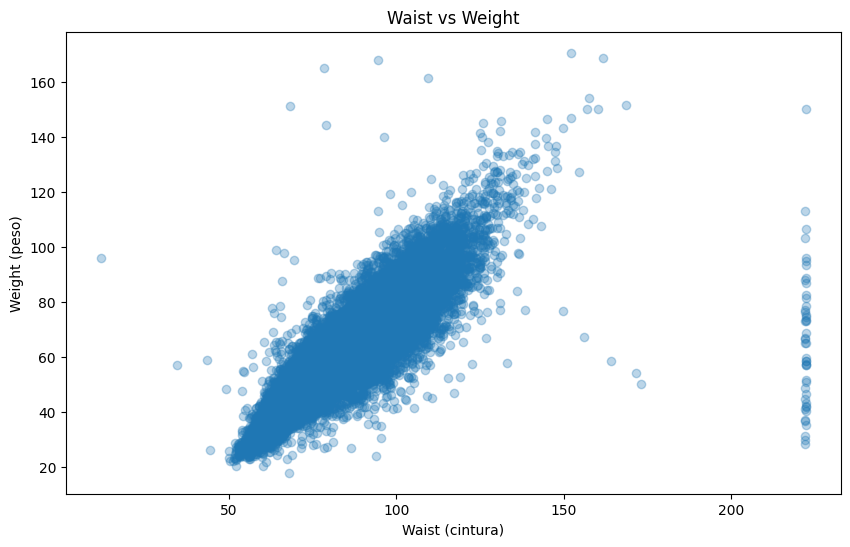

In [45]:

plt.figure(figsize=(10, 6))

plt.scatter(
    waist_weight['cintura'],
    waist_weight['peso'],
    alpha=0.3
)

plt.title('Waist vs Weight')
plt.xlabel('Waist (cintura)')
plt.ylabel('Weight (peso)')
plt.show()

In [47]:
waist_weight.describe()

,peso,cintura
count,18032.000000,18032.000000
mean,64.680127,87.778529
std,17.804136,16.950062
min,18.000000,11.900000
25%,52.700000,76.000000
50%,63.800000,87.250000
75%,75.650000,98.000000
max,170.600000,222.220000


### Sex 1


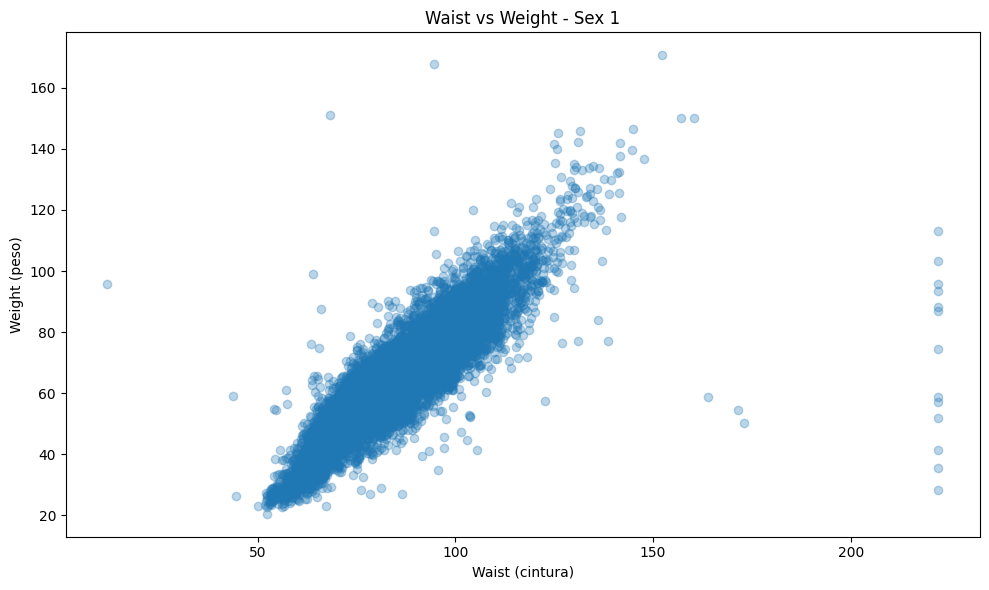

In [39]:

waist_weight_sex1 = sex_1[['peso', 'cintura']].dropna()

plt.figure(figsize=(10, 6))

plt.scatter(
    waist_weight_sex1['cintura'],
    waist_weight_sex1['peso'],
    alpha=0.3
)

plt.title('Waist vs Weight - Sex 1')
plt.xlabel('Waist (cintura)')
plt.ylabel('Weight (peso)')
plt.tight_layout()
plt.show()

In [42]:
-3-3-#############3waist_weight_sex1.describe()

,peso,cintura
count,8154.000000,8154.000000
mean,67.131228,87.502601
std,18.982250,16.766449
min,20.550000,11.900000
25%,54.700000,75.200000
50%,66.750000,87.350000
75%,79.250000,98.300000
max,170.600000,222.220000


### Sex 2

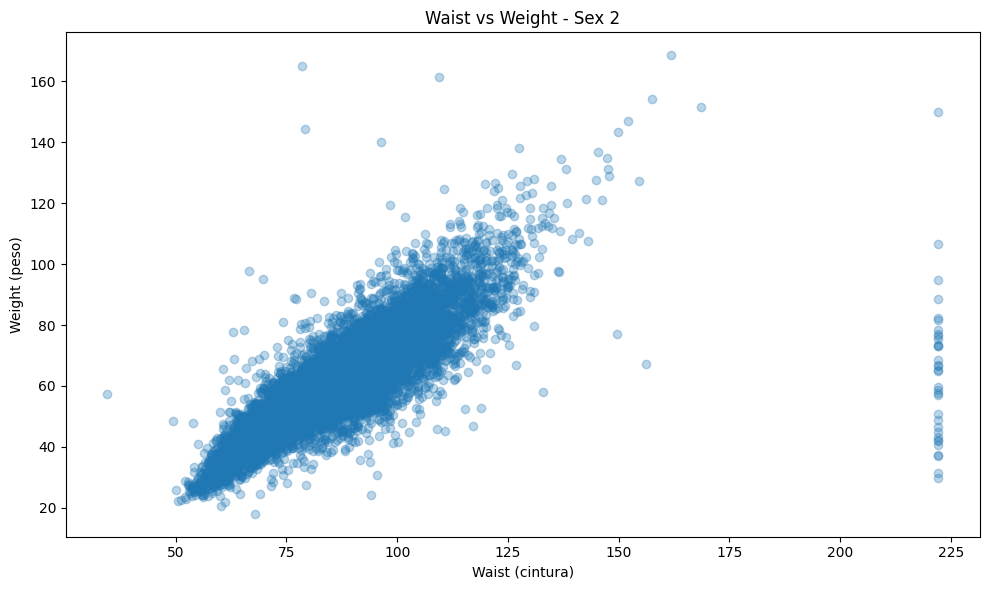

In [40]:

waist_weight_sex2 = sex_2[['peso', 'cintura']].dropna()

plt.figure(figsize=(10, 6))

plt.scatter(
    waist_weight_sex2['cintura'],
    waist_weight_sex2['peso'],
    alpha=0.3
)

plt.title('Waist vs Weight - Sex 2')
plt.xlabel('Waist (cintura)')
plt.ylabel('Weight (peso)')
plt.tight_layout()
plt.show()

In [41]:
waist_weight_sex2.describe()

,peso,cintura
count,9878.000000,9878.000000
mean,62.656815,88.006300
std,16.498223,17.097636
min,18.000000,34.550000
25%,51.362500,76.350000
50%,61.400000,87.200000
75%,72.243750,97.800000
max,168.600000,222.220000


## Answer to questions


1.   **¿How are the distributions (symmetric, asymmetric, right-skewed, left-skewed)?**

From the general visualization of [measurements' histogram](scrollTo=PKpROTsp7MAC&line=1&uniqifier=1) , weight's histogram has an asymmetricn and right-skewed distribution, since most of the observation lay in the 50-80 range. However, the histogram also shows a tail that extends toward higher values.  The waist histogram, are more concentrated to its central values, with a slight righ-skewedness.

Age also shows a right-skewed distribution, while the hip histogram is more concentrated to the center, with a slight right-skew and extreme values. Contrary to the previous, heigh has an overall bell-shaoed , which suggest normal distribution.


2.   **When visualizing the histograms, are their atypical values?**

I observed some atypical values in the weight, waist and hip measurements, since ther are values extremly far from the concetrated observations. This atypical values are easily shown in the boxplots.

3.   **How is the behaviour of weight with respect to the waist?**

From the scatter plot of the distribution diagram, I observed that both variables are positebly correlated, since as weight increases so does the waist measurements. Which this pattern is also shown when divided by sexs.

4.   **When visualizing the dispersion diagram between the variabels " weight" and "waist", are their atypical values?**

Yes, as seen in the scatter plot, there is a tail that goes to higher values. Also, when reaching the  waist measurement near 225, there appears to be some observation that form a line, which is extreamly weird.

5.   **Divide the data between men and women, and repeat the analysis. Comment personal conclusions.**

After separating the data's visualization into sex slicing, there is significan change in the descrptitive statistics values, for example women "sex 2" show higher hip measurements, while sex 1 tends to have higher weight and heigtht values. As the distribution analysis of wast and weight diagram, both sexs show positive relationship. The differnece is where's the specific mean, sex 1 has the average of : 67.131228 weight &	87.502601 waist, while sex 2 has : 62.656815 weight &	88.006300 waist.

Oddly enough,each of the sex shows the same weird obervations in the 225 waist measuremnt, which would suggest me they are atypical observations.